# Simulated Annealing para descifrar al Zodiac

**Profesor:** Avelio Sepúlveda

**Profesores Auxiliares:** Claudio López y Fraick Reyes

**Ayudante:** Antonio Rojo

**Integrantes:** Diego Palacios y Nicolás Villarroel

## Paquetes a importar

In [ ]:
import numpy as np, math, time, random, matplotlib.pyplot as plt, seaborn as sns
from IPython.display import clear_output
from collections import Counter
from collections import defaultdict
from math import comb
from matplotlib.patches import FancyArrowPatch
from matplotlib.colors import Normalize

## Configuraciones iniciales

In [ ]:
# Cuadrigramas
!wget https://raw.githubusercontent.com/gibsjose/statistical-attack/master/english-quadgrams.txt

!ls -l

# Trigramas
!wget https://raw.githubusercontent.com/gibsjose/statistical-attack/master/english-trigrams.txt

!ls -l

# Bigramas
!wget https://raw.githubusercontent.com/gibsjose/statistical-attack/master/english-bigrams.txt

!ls -l

--2026-11-17 20:42:52--  https://raw.githubusercontent.com/gibsjose/statistical-attack/master/english-quadgrams.txt
Resolving raw.githubusercontent.com (raw.githubusercontent.com)... 185.199.108.133, 185.199.109.133, 185.199.110.133, ...
Connecting to raw.githubusercontent.com (raw.githubusercontent.com)|185.199.108.133|:443... connected.
HTTP request sent, awaiting response... 200 OK
Length: 3289600 (3.1M) [text/plain]
Saving to: ‘english-quadgrams.txt’

english-quadgrams.t 100%[===================>]   3.14M  --.-KB/s    in 0.07s   

2026-11-17 20:42:53 (44.6 MB/s) - ‘english-quadgrams.txt’ saved [3289600/3289600]

total 3220
-rw-r--r-- 1 root root 3289600 Nov 17 20:42 english-quadgrams.txt
drwxr-xr-x 1 root root    4096 Oct 26 22:18 sample_data
--2026-11-17 20:42:53--  https://raw.githubusercontent.com/gibsjose/statistical-attack/master/english-trigrams.txt
Resolving raw.githubusercontent.com (raw.githubusercontent.com)... 185.199.108.133, 185.199.109.133, 185.199.110.133, ...
Connec

In [ ]:
path1 = 'english-trigrams.txt'
path2 = 'english-bigrams.txt'

def cargar_ngramas(path='english-quadgrams.txt'):
  ngramas = {}
  total = 0

  with open(path, 'r', encoding='utf-8') as f:
    for line in f:
      linea = line.strip().split()
      if len(linea) == 2:
        ngrama, frecuencia = linea[0], float(linea[1])

        ngramas[ngrama] = frecuencia

        total += frecuencia

  for ngrama in ngramas:
    ngramas[ngrama] = math.log10(ngramas[ngrama] / total)

  probabilidad = math.log10(0.01 / total)

  return ngramas, probabilidad

cuadrigramas, penalizacion = cargar_ngramas()
trigramas, penalizacion2 = cargar_ngramas(path1)
bigramas, penalizacion3 = cargar_ngramas(path2)

In [ ]:
Sigma =  {
   'A' : "◬",
   'B' : "◫",
   'C' : "⟁",
   'D' : "⌖",
   'E' : "⎈",
   'F' : "⍜",
   'G' : "⍤",
   'H' : "⎅",
   'I' : "☊",
   'J' : "⌕",
   'K' : "⎍",
   'L' : "⎋",
   'M' : "⏁",
   'N' : "⏃",
   'O' : "⏈",
   'P' : "⌰",
   'Q' : "⌿",
   'R' : "⍎",
   'S' : "⍕",
   'T' : "⍖",
   'U' : "⍗",
   'V' : "⍘",
   'W' : "⍙",
   'X' : "⍚",
   'Y' : "⍛",
   'Z' :"⍁"
}

## Funciones para el Simulated Annealing

In [ ]:
def puntaje(M, n = 4):
  assert n in [2, 3, 4], "Elegir bigrama, trigrama o cuadrigrama"
  texto = ''.join(M.flatten())
  ptje = 0
  #n = letras

  for i in range(len(texto) - n + 1):
    if n == 4:
      cuadrigrama = texto[i:i+n]
      ptje += cuadrigramas.get(cuadrigrama, penalizacion)

    elif n == 3:
      trigrama = texto[i:i+n]
      ptje += trigramas.get(trigrama, penalizacion2)

    elif n == 2:
      bigrama = texto[i:i+n]
      ptje += bigramas.get(bigrama, penalizacion3)

    else:
      raise ValueError("Sólo se admite n en {2,3,4}")

  return -ptje

In [ ]:
def crear_condicion_inicial(cifrado, simbolos_sigma):
  frecuencias = Counter(cifrado)
  simbolos_ordenados = [item[0] for item in frecuencias.most_common()]
  mas_frecuentes = list('ETAOINSHRDLCUMFWYPVBGKJQXZ')

  condicion_inicial = {}
  ingles_usado = set()

  for i, simbolo in enumerate(simbolos_ordenados):
    if i < len(mas_frecuentes):
      condicion_inicial[simbolo] = mas_frecuentes[i]
      ingles_usado.add(mas_frecuentes[i])

  ingles_restantes = [c for c in mas_frecuentes if c not in ingles_usado]
  for simbolo in simbolos_sigma:
    if simbolo not in condicion_inicial:
      condicion_inicial[simbolo] = ingles_restantes.pop(0) if ingles_restantes else 'X'

  return condicion_inicial

In [ ]:
def decodificar(cifrado, diccionario):
  return ''.join(diccionario.get(c, c) for c in cifrado)

A continuación, se define una función que permite calcular las temperaturas del algoritmo mediante los siguientes esquemas:

$\bullet$ **Esquema geométrico:** Para $n\in\mathbb{N}$ se define
$$
T_n = \alpha^n T_0,
$$
con $\alpha>0$.

$\bullet$ **Esquema lineal:** Para $n\in\mathbb{N}$ se define
$$
T_n = \max\{T_{\min}, T_0 - cn\},
$$
con $c>0$.

$\bullet$ **Esquema por potencias:** Para $n\in\mathbb{N}$ se define
$$
T_n = \frac{T_0}{(1 + cn)^p},
$$
con $c,p>0$.

En lo anterior, $T_0$ denota una temperatura inicial y $T_\min$ una temperatura pequeña para evitar valores negativos, en las simulaciones se usó
$$
 \alpha = 0.999,\quad c= 0.001,\quad p\in\{1,\ 0.7\},\quad T_\min = 10^{-80}
$$

In [ ]:
def calcular_temperatura(
    n,
    T0=100,
    esquema="geometrico",
    alpha=0.9999,
    c=0.001,
    p=1
):

    if esquema == "geometrico":
        return T0 * alpha**n

    elif esquema == "lineal":
        return max(1e-80, T0 - c*n)

    elif esquema == "racional":
        return T0 / (1 + c*n)

    elif esquema == "potencias":
        return T0 / (1 + c*n)**p

    else:
        raise ValueError("Esquema desconocido")

## Encriptación del mensaje y Variables globales

In [ ]:
def encriptar_mensaje(m):
  # De momento se asume que será un mensaje específico para que quepa en una cuadrícula de 20x17, se realiza además una trasposición 1,2 (en caballo)

  m = m.replace(" ","")

  m = m.upper()

  filas = 20

  columnas = 17

  cod_base = ord('A')

  M = np.array(list(m)).reshape(filas, columnas)


  print("Mensaje original (en cuadrícula):")

  print()

  print(M)

  print()

  time.sleep(2)

  clear_output(wait=True)

  # Cifrado de Trasposición

  M_caballo = np.copy(M)

  texto = ''.join(M.flatten())

  n = filas*columnas

  for k in range(n):

    i = k % filas

    j = (2*k) % columnas
    M_caballo[i, j] = texto[k]

  print(f'Mensaje traspuesto (Uma-style)')

  print()

  print(M_caballo)

  print()

  time.sleep(2)

  clear_output(wait=True)

  # Cifrado de sustitución

  encriptar_1 = np.vectorize(lambda x: Sigma.get(x, x))

  M_encriptado_2 = encriptar_1(M_caballo)

  print("Mensaje encriptado (en cuadrícula):")

  print()

  print(M_encriptado_2)

  return M_encriptado_2

In [ ]:
# Mensaje original
s = "We are no strangers to love You know the rules and so do I A full commitment is what I am thinking of You would not get this from any other guy I just wanna tell you how I am feeling Gotta make you understand Never gonna give you up Never gonna let you down Never gonna run around and desert you Never gonna make you cry Never gonna say goodbye Never gonna tell a lie and hurt you  If you laughed then leave a like and subscribe"

# Cuadrícula encriptada
M = encriptar_mensaje(s)

# Cuadrícula objetivo
s = s.replace(" ","")

s = s.upper()
M_original = np.array(list(s)).reshape(20, 17)

# Lista de caracteres
lista_caract = []

for k in Sigma.keys():
  lista_caract.append(Sigma[k])

Mensaje encriptado (en cuadrícula):

[['⍙' '☊' '⏃' '⍗' '⏈' '⏈' '⍘' '⏈' '⏃' '⏈' '⏈' '◬' '⍕' '⏁' '⍖' '⏃' '⏈']
 ['⌖' '⏃' '⎈' '⍕' '◬' '⍗' '⏃' '⍗' '⎈' '⍗' '⍤' '⍙' '⏃' '⍘' '⏈' '◬' '◬']
 ['⏃' '⏃' '◬' '⏃' '◬' '⍙' '⍖' '⌰' '⏃' '☊' '⍛' '⍙' '⍤' '⏃' '⏃' '⎈' '⌖']
 ['◬' '⏈' '⍛' '⌖' '⏃' '◬' '⍎' '⎅' '⎈' '⏃' '◬' '⍜' '⏈' '⏈' '⏈' '⏃' '◬']
 ['⎈' '⍕' '⎋' '☊' '⏈' '⏃' '⌖' '⍖' '⎈' '◬' '⎋' '⎈' '⏁' '⍛' '⍗' '⍗' '⍖']
 ['⎋' '⍖' '⍘' '◬' '☊' '◬' '⍖' '⎈' '⌖' '⎈' '⏃' '⍖' '⎋' '⍘' '◬' '⏈' '⎍']
 ['⍗' '⏃' '⌖' '◬' '⎈' '⍛' '⎍' '⍜' '⎅' '⍘' '⎈' '⎋' '⏈' '☊' '⍛' '⎈' '⎍']
 ['⍎' '⎈' '⎋' '⏈' '⏃' '⏁' '⍎' '⍤' '⎈' '⍗' '⎈' '⎈' '⍕' '⎋' '⍕' '◬' '⏈']
 ['⏁' '⍗' '⍤' '⍛' '◬' '⍙' '⏈' '◬' '⍤' '⏈' '◬' '⎋' '⍎' '⍎' '⎈' '◬' '⍖']
 ['⎋' '⍎' '⍖' '⎅' '⏈' '⏈' '⍗' '⍖' '⍖' '⎍' '⏈' '⏈' '⏃' '⎋' '⍤' '⍤' '⍎']
 ['⏈' '⍖' '☊' '◬' '⎅' '⏈' '⏃' '⍗' '⍤' '⎅' '⍤' '⎈' '⏃' '⌖' '⌖' '⟁' '⍗']
 ['⏈' '⍛' '⏃' '⍛' '⎈' '⏃' '☊' '⍙' '⏃' '⟁' '⎅' '⎈' '⎈' '⍛' '⏃' '◫' '⍕']
 ['⍛' '⍗' '⏁' '☊' '⏃' '⏈' '◬' '⍤' '⏃' '☊' '◬' '⍎' '⎈' '⍎' '⍖' '⏈' '◬']
 ['⍗' '⍎' '⎈' '◫' '⏁' '⌕' '◬' '⍗' '⏃' '⎈

## Definición del algoritmo

### Recorriendo diagonalmente

In [ ]:
# Este código asume que las decimaciones son válidas
def SimulatedAnnealing_decimaciones(
    M,
    Sigma_simbolos,
    df=1,
    dc=2,
    Tiempo=500000,
    M_objetivo=None,
    esquema = "geometrico",
    p = 1,
    T0 = 100,
    ngrama = 4
):

    filas, columnas = M.shape

    n = filas * columnas

    texto = [''] * n

    for k in range(n):
        i = (df * k) % filas
        j = (dc * k) % columnas
        texto[k] = M[i, j]

    cifrado = ''.join(texto)

    Sigma0 = crear_condicion_inicial(
        cifrado, Sigma_simbolos
    )

    s0 = decodificar(cifrado, Sigma0)

    M0 = np.array(list(s0)).reshape(filas, columnas)

    F0 = puntaje(M0, ngrama)

    # Puntaje objetivo
    F_objetivo = (
        puntaje(M_objetivo, ngrama)
        if M_objetivo is not None
        else None
    )

    T = T0
    T_min = 1e-80

    mejor_Sigma = Sigma0.copy()
    mejor_mensaje = s0
    mejor_F = F0
    mejor_M = M0.copy()

    paso = 0

    # Historiales
    historial_actual = [F0]
    historial_mejor = [mejor_F]

    # Simulated Annealing
    while paso < Tiempo and T > T_min:

        Sigma_n = Sigma0.copy()

        n1, n2 = random.sample(
            list(Sigma_n.keys()), 2
        )

        Sigma_n[n1], Sigma_n[n2] = (
            Sigma_n[n2], Sigma_n[n1]
        )

        s_n = decodificar(cifrado, Sigma_n)

        M_n = np.array(list(s_n)).reshape(
            filas, columnas
        )

        F_n = puntaje(M_n, ngrama)

        dF = F_n - F0

        if dF <= 0 or random.random() < math.exp(-dF / T):

            Sigma0 = Sigma_n
            F0 = F_n
            M0 = M_n.copy()

            if F0 < mejor_F:

                mejor_F = F_n
                mejor_mensaje = s_n
                mejor_Sigma = Sigma_n.copy()
                mejor_M = M_n.copy()

        paso += 1
        T = calcular_temperatura(
            paso,
            T0 = T0,
            esquema = esquema,
            p = p
        )

        historial_actual.append(F0)
        historial_mejor.append(mejor_F)

  #Los gráficos se hicieron con ayuda de IA. Los ajustes de algunos parámetros se ajustaron manualmente
    fig, (ax1, ax2) = plt.subplots(
        1, 2,
        figsize=(17, 7),
        gridspec_kw={'width_ratios': [1, 1.3]}
    )


    ax1.axis('off')

    ax1.set_title(
        f"Mejor mensaje encontrado\n"
        f"Puntaje: {mejor_F:.4f}",
        fontsize=20
    )

    tabla = ax1.table(
        cellText=mejor_M,
        loc='center',
        cellLoc='center'
    )

    tabla.auto_set_font_size(False)
    tabla.set_fontsize(8)
    tabla.scale(1.2, 1.5)

    iteraciones = range(len(historial_actual))

    ax2.plot(
        iteraciones,
        historial_actual,
        color='lightsteelblue',
        alpha=0.7,
        linewidth=0.8,
        label='Puntaje actual'
    )

    ax2.plot(
        iteraciones,
        historial_mejor,
        color='royalblue',
        linewidth=1.5,
        label='Mejor puntaje'
    )

    if F_objetivo is not None:
        ax2.axhline(
            y=F_objetivo,
            color='red',
            linestyle='--',
            linewidth=1.5,
            label=f'Puntaje objetivo: {F_objetivo:.4f}'
        )

    ax2.set_title("Evolución del puntaje",fontsize=24)
    ax2.set_xlabel("Iteración", fontsize=20)
    ax2.set_ylabel("Puntaje", fontsize=20)
    ax2.grid(True, alpha=0.3)
    ax2.legend(fontsize=14)

    fig.suptitle(
        f"Simulated Annealing - Decimación ({df},{dc})\n"
        f"Iteraciones realizadas: {paso}",
        fontsize=28
    )

    plt.tight_layout()
    plt.show()
    #Termina código generado con IA y modificado manualmente

    return mejor_mensaje, mejor_Sigma, mejor_M

### Estimando únicamente las posiciones en la grilla

In [ ]:
def estimar_posiciones(M, Sigma_simbolos, Tiempo = 10000, T_min = 1e-25, dic = None, esquema = "geometrico", p = 1, T0 = 100, ngrama = 4):
  filas, columnas = M.shape

  n = filas*columnas

  texto = [''] * n

  for i in range(filas):
    for j in range(columnas):
      texto[i*columnas + j] = M[i, j]

  cifrado = ''.join(texto)

  if dic == None:
    Sigma0 = crear_condicion_inicial(cifrado, Sigma_simbolos)
  else:
    Sigma0 = dic
  s0 = decodificar(cifrado, Sigma0)
  M0 = np.array(list(s0)).reshape(filas, columnas)
  F0 = puntaje(M0, ngrama)

  T = T0
  #T_min = 1e-5

  mejor_Sigma = Sigma0.copy()
  mejor_mensaje = s0
  mejor_F = F0
  mejor_M = M0.copy()

  paso = 0


  pasos = []
  valores = []
  historial_actual = [F0]

  while True:
    if paso > Tiempo:
      print("Detención por pasos totales")
      break
    if T < T_min:
      print("Detención por temperatura")
      break

    M_n = M0.copy()

    idx = np.random.choice(M.size, size=2, replace=False)
    pos = np.unravel_index(idx, M.shape)

    filas, columnas = pos
    pos1 = filas[0], columnas[0]
    pos2 = filas[1], columnas[1]

    M_n[pos1], M_n[pos2] = M_n[pos2], M_n[pos1]

    s_n = ''.join(M_n.flatten())
    F_n = puntaje(M_n, ngrama)

    dF = F_n - F0

    U = np.random.uniform(0, 1)

    if dF < 0 or np.log(U) <= -dF/T: #para evitar overflow, se comparan los logaritmos
      F0 = F_n
      M0 = M_n.copy()

      if F0 < mejor_F:
        mejor_F = F_n
        mejor_mensaje = ''.join(M0.flatten())

        mejor_M = M0.copy()

    #ver el mensaje cada 10000 pasos
    if paso % 10000 == 0:
      clear_output(wait=True)
      print(f'--- Paso {paso:e} | Temperatura: {T:e} ---')
      print(f'Mejor Funcion (Energía/Puntaje): {mejor_F}')
      print("Mejor Matriz M:\n", mejor_M)


    pasos.append(paso)
    valores.append(mejor_F)
    paso += 1
    T = calcular_temperatura(
        paso,
        T0 = T0,
        esquema = esquema,
        p = p
    )

    historial_actual.append(F0)

  #Comienza código generado con IA y modificado manualmente
  fig, (ax1, ax2) = plt.subplots(
      1, 2,
      figsize=(17, 7),
      gridspec_kw={'width_ratios': [1, 1.3]}
  )

  ax1.axis('off')

  ax1.set_title(
      f"Mejor mensaje encontrado\n"
      f"Puntaje: {mejor_F:.4f}",
      fontsize=20
  )

  tabla = ax1.table(
      cellText=mejor_M,
      loc='center',
      cellLoc='center'
  )

  tabla.auto_set_font_size(False)
  tabla.set_fontsize(8)
  tabla.scale(1.2, 1.5)

  iteraciones = range(len(historial_actual))

  ax2.plot(
        iteraciones,
        historial_actual,
        color='lightsteelblue',
        alpha=0.7,
        linewidth=0.8,
        label='Puntaje actual'
    )

  ax2.plot(
      pasos,
      valores,
      color='royalblue',
      linewidth=1.5,
      label='Mejor puntaje'
  )

  ax2.axhline(
      y=1509,
      color='red',
      linestyle='--',
      linewidth=1.5,
      label='Puntaje mensaje original'
  )

  ax2.set_title("Evolución del puntaje",fontsize=24)
  ax2.set_xlabel("Iteración", fontsize=20)
  ax2.set_ylabel("Puntaje", fontsize=20)
  ax2.grid(True, alpha=0.3)
  ax2.legend(fontsize=14)

  fig.suptitle(
      f"Simulated Annealing - Posiciones\n"
      f"Iteraciones realizadas: {paso}",
      fontsize=28
  )

  # plt.savefig(f"Simulated Annealing - Posiciones - Esquema {esquema}.jpg")
  plt.tight_layout()
  plt.show()
  plt.close()
  #Termina código generado con IA y modificado manualmente

  return mejor_mensaje, mejor_M

In [ ]:
def estimar_alfabeto_posiciones(M, Sigma_simbolos, Tiempo = 10000, T_min = 1e-25, dic = None, peso_grilla = 0.6, esquema = "geometrico", p = 1, T0 = 100, ngrama = 4):
  filas, columnas = M.shape

  n = filas*columnas

  texto = [''] * n

  for i in range(filas):
    for j in range(columnas):
      texto[i*columnas + j] = M[i, j]

  cifrado = ''.join(texto)

  if dic == None:
    Sigma0 = crear_condicion_inicial(cifrado, Sigma_simbolos)
  else:
    Sigma0 = dic
  s0 = decodificar(cifrado, Sigma0)
  M0 = np.array(list(s0)).reshape(filas, columnas)
  F0 = puntaje(M0, ngrama)

  T = T0

  mejor_Sigma = Sigma0.copy()
  mejor_mensaje = s0
  mejor_F = F0
  mejor_M = M0.copy()

  paso = 0

  pasos = []
  valores = []
  historial_actual = [F0]

  while True:
    if paso > Tiempo:
      print("Detención por pasos totales")
      break
    if T < T_min:
      print("Detención por temperatura")
      break


    Sigma_n = Sigma0.copy()
    M_n = M0.copy()

    if np.random.rand() >= peso_grilla:
      n1, n2 = random.sample(list(Sigma_n.keys()), 2)
      Sigma_n[n1], Sigma_n[n2] = Sigma_n[n2], Sigma_n[n1]

      s_n = decodificar(cifrado, Sigma_n)
      M_n = np.array(list(s_n)).reshape(filas, columnas)
    else:

      idx = np.random.choice(M.size, size=2, replace=False)
      pos = np.unravel_index(idx, M.shape)

      fila_n, columna_n = pos
      pos1 = fila_n[0], columna_n[0]
      pos2 = fila_n[1], columna_n[1]

      M_n[pos1], M_n[pos2] = M_n[pos2], M_n[pos1]
      s_n = ''.join(M_n.flatten())


    F_n = puntaje(M_n, ngrama)

    dF = F_n - F0


    U = np.random.uniform(0, 1)

    if dF < 0 or np.log(U) <= -dF/T: #para evitar overflow, se comparan los logaritmos
      Sigma0 = Sigma_n.copy()
      F0 = F_n
      M0 = M_n.copy()

      if F0 < mejor_F:
        mejor_F = F_n
        mejor_mensaje = s_n
        mejor_Sigma = Sigma_n.copy()
        mejor_M = M0.copy()

    #ver el mensaje cada ciertos pasos
    if paso % 1e4 == 0:
      clear_output(wait=True)
      print(f'--- Paso {paso:e} | Temperatura: {T:e} ---')
      print(f'Mejor Funtion (Energía/Puntaje): {mejor_F}')
      print("Mejor Matriz M:\n", mejor_M)
      print("Mejor Sigma:\n", mejor_Sigma)

    pasos.append(paso)
    valores.append(mejor_F)
    paso += 1
    T = calcular_temperatura(
        paso,
        T0 = T0,
        esquema = esquema,
        p = p
    )

    historial_actual.append(F0)

  #Comienza código generado con IA y modificado manualmente
  fig, (ax1, ax2) = plt.subplots(
      1, 2,
      figsize=(17, 7),
      gridspec_kw={'width_ratios': [1, 1.3]}
  )

  ax1.axis('off')

  ax1.set_title(
      f"Mejor mensaje encontrado\n"
      f"Puntaje: {mejor_F:.4f}",
      fontsize=20
  )

  tabla = ax1.table(
      cellText=mejor_M,
      loc='center',
      cellLoc='center'
  )

  tabla.auto_set_font_size(False)
  tabla.set_fontsize(8)
  tabla.scale(1.2, 1.5)

  iteraciones = range(len(historial_actual))

  ax2.plot(
        iteraciones,
        historial_actual,
        color='lightsteelblue',
        alpha=0.7,
        linewidth=0.8,
        label='Puntaje actual'
    )


  ax2.plot(
      pasos,
      valores,
      color='royalblue',
      linewidth=1.5,
      label='Mejor puntaje'
  )

  ax2.axhline(
      y=1509,
      color='red',
      linestyle='--',
      linewidth=1.5,
      label='Puntaje mensaje original'
  )

  ax2.set_title("Evolución del puntaje",fontsize=24)
  ax2.set_xlabel("Iteración",fontsize=20)
  ax2.set_ylabel("Puntaje",fontsize=20)
  ax2.grid(True, alpha=0.3)
  ax2.legend(fontsize=14)

  fig.suptitle(
      f"Simulated Annealing - Alfabeto y posiciones\n"
      f"Iteraciones realizadas: {paso}",
      fontsize=28
  )

  # fig.savefig(f"Simulated Annealing - Alfabeto y posiciones - Esquema {esquema}.jpg")
  plt.tight_layout()
  plt.show()
  plt.close()
  #Termina código generado con IA y modificado manualmente

  return mejor_mensaje, mejor_Sigma, mejor_M

## Ataque a doble capa

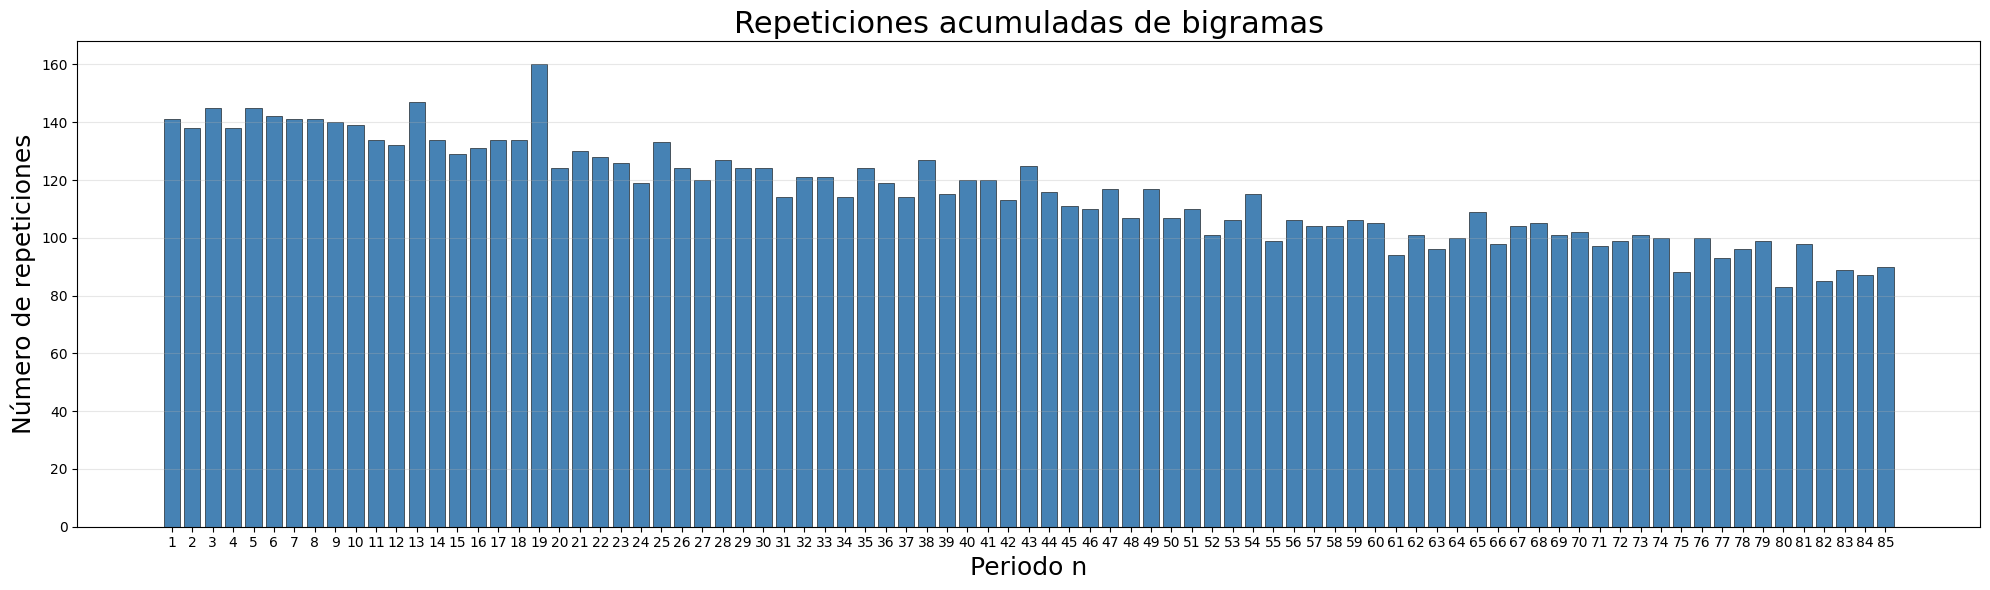


Periodos con más repeticiones:

Periodo 19: 160 repeticiones
Periodo 13: 147 repeticiones
Periodo  3: 145 repeticiones
Periodo  5: 145 repeticiones
Periodo  6: 142 repeticiones
Periodo  1: 141 repeticiones
Periodo  7: 141 repeticiones
Periodo  8: 141 repeticiones
Periodo  9: 140 repeticiones
Periodo 10: 139 repeticiones

Bigramas repetidos para periodo 19:

('⍘', '⎈'): 9 apariciones, 8 repeticiones en posiciones [6, 30, 87, 98, 111, 274, 280, 284, 285]
('⎈', '⍎'): 9 apariciones, 8 repeticiones en posiciones [106, 129, 130, 150, 198, 230, 293, 297, 299]
('⏃', '◬'): 8 apariciones, 7 repeticiones en posiciones [2, 37, 42, 48, 195, 201, 208, 260]
('⏈', '⍗'): 8 apariciones, 7 repeticiones en posiciones [5, 7, 63, 64, 158, 209, 292, 317]
('⏃', '⏃'): 8 apariciones, 7 repeticiones en posiciones [15, 18, 23, 29, 47, 176, 182, 189]
('⍛', '⏈'): 8 apariciones, 7 repeticiones en posiciones [44, 53, 81, 116, 139, 190, 200, 273]
('⍎', '⍤'): 7 apariciones, 6 repeticiones en posiciones [119, 125, 148,

In [ ]:
def calcular_repeticiones_acumuladas(M, a=1, b=85):

    C = ''.join(M.flatten())
    N = len(C)

    resultados = {}

    for n in range(a, b + 1):

        bigramas = defaultdict(list)

        for i in range(N - n):
            bigrama = (C[i], C[i+n])
            bigramas[bigrama].append(i)

        total = sum(
            len(posiciones) - 1
            for posiciones in bigramas.values()
        )

        resultados[n] = {
            "total": total,
            "bigramas": dict(bigramas)
        }

    return resultados

#Esta función fue creada en gran parte con IA, con modificaciones manuales
def graficar_repeticiones_acumuladas(resultados):

    periodos = list(resultados.keys())

    valores = [
        resultados[n]["total"]
        for n in periodos
    ]

    plt.figure(figsize=(20, 6))

    plt.bar(
        periodos,
        valores,
        color="steelblue",
        edgecolor="black",
        linewidth=0.4
    )

    plt.title("Repeticiones acumuladas de bigramas", fontsize=22)
    plt.xlabel("Periodo n", fontsize=18)
    plt.ylabel("Número de repeticiones", fontsize=18)
    plt.xticks(periodos)
    plt.grid(axis="y", alpha=0.3)

    plt.tight_layout()
    plt.show()
#Termina creación con IA



def mostrar_periodos_mayores_repeticiones(resultados, cantidad=10):

    mejores = sorted(
        resultados.items(),
        key=lambda x: x[1]["total"],
        reverse=True
    )[:cantidad]

    print("\nPeriodos con más repeticiones:\n")

    for n, datos in mejores:
        print(
            f"Periodo {n:2d}: "
            f"{datos['total']} repeticiones"
        )


def consultar_bigramas_repetidos(resultados, periodo):

    print(f"\nBigramas repetidos para periodo {periodo}:\n")

    bigramas = resultados[periodo]["bigramas"]

    repetidos = {
        bigrama: posiciones
        for bigrama, posiciones in bigramas.items()
        if len(posiciones) >= 2
    }

    for bigrama, posiciones in sorted(
        repetidos.items(),
        key=lambda x: len(x[1]),
        reverse=True
    ):

        print(
            f"{bigrama}: {len(posiciones)} apariciones, "
            f"{len(posiciones)-1} repeticiones "
            f"en posiciones {posiciones}"
        )


resultados = calcular_repeticiones_acumuladas(M, 1, 85)

graficar_repeticiones_acumuladas(resultados)

mostrar_periodos_mayores_repeticiones(resultados, 10)

consultar_bigramas_repetidos(resultados, 19)

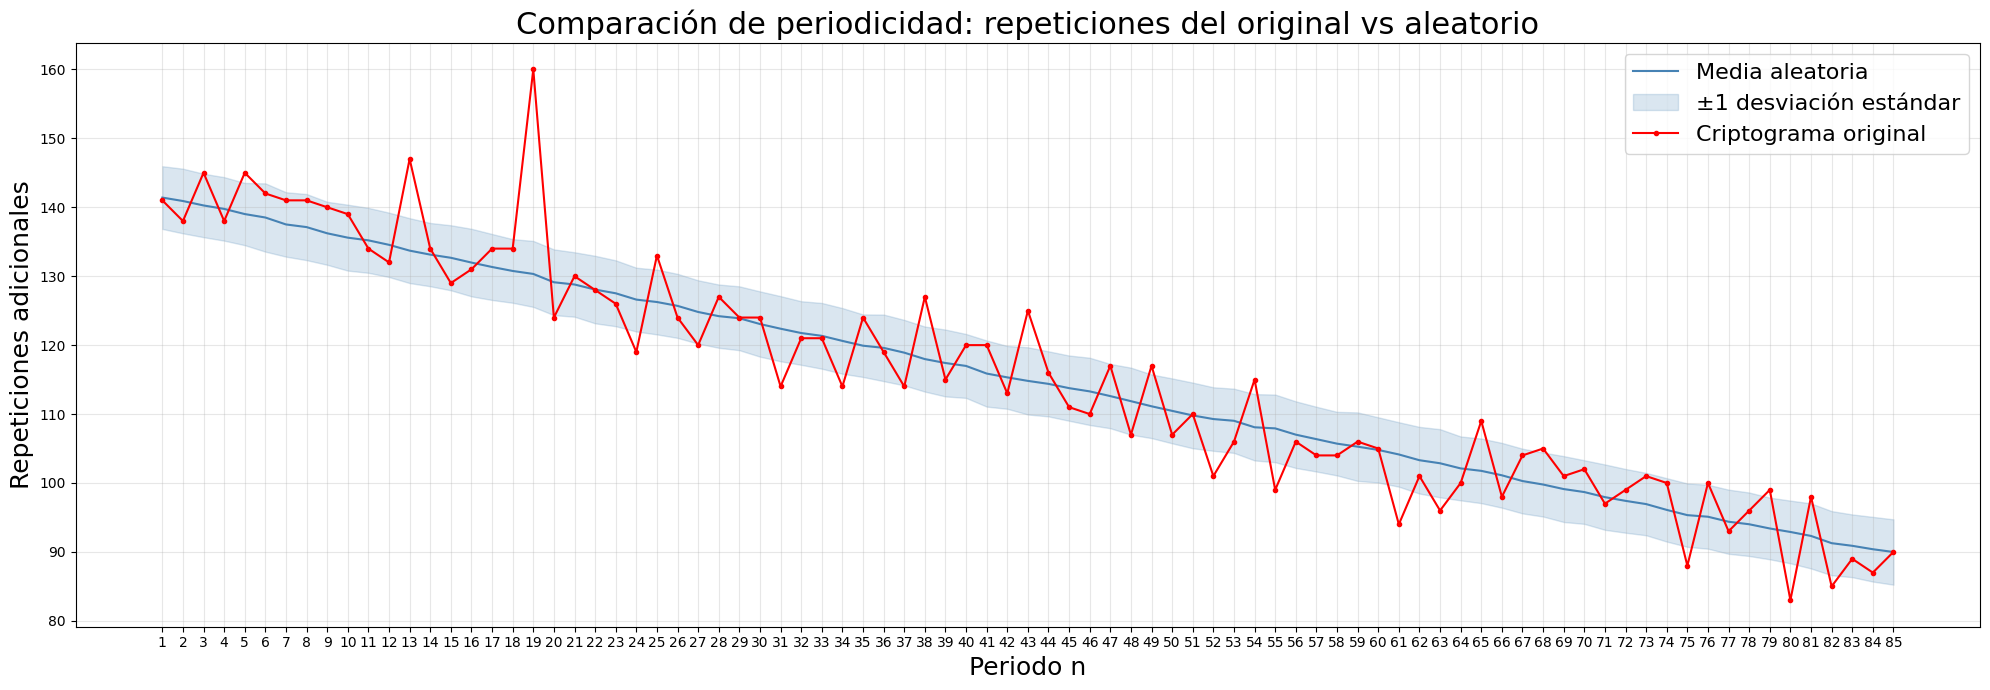


Periodos más destacables:

Periodo   Original    Media       Desv.       Percentil   p-valor     
19        160         130.33      4.78        100.00      0.0010      
13        147         133.71      4.70        99.80       0.0060      
43        125         114.81      4.87        99.00       0.0190      
38        127         117.97      4.72        97.70       0.0420      
65        109         101.76      4.68        94.90       0.0749      
25        133         126.25      4.70        94.50       0.0959      
54        115         108.08      4.81        93.40       0.0959      
5         145         139.01      4.51        92.40       0.1169      
49        117         111.13      4.61        91.10       0.1249      
79        99          93.40       4.47        91.50       0.1289      
81        98          92.32       4.72        90.70       0.1339      
68        105         99.78       4.64        89.00       0.1568      
76        100         95.11       4.64        87.

In [ ]:
def contar_repeticiones(texto, n):

    pares = [
        (texto[i], texto[i+n])
        for i in range(len(texto)-n)
    ]

    frecuencias = Counter(pares)

    return sum(
        f - 1
        for f in frecuencias.values()
    )


def evaluar_aleatoriedad_repeticiones(
    M, a=2, b=85,
    iteraciones=1000, semilla=None
):

    C = np.array(list(''.join(M.flatten())))
    N = len(C)

    periodos = np.arange(a, b+1)

    originales = np.array([
        contar_repeticiones(C, n)
        for n in periodos
    ])

    simulados = np.zeros(
        (iteraciones, len(periodos)),
        dtype=int
    )

    rng = np.random.default_rng(semilla)

    for k in range(iteraciones):

        aleatorio = rng.permutation(C)

        for j, n in enumerate(periodos):

            simulados[k, j] = contar_repeticiones(
                aleatorio, n
            )

    medias = np.mean(simulados, axis=0)

    desviaciones = np.std(
        simulados, axis=0, ddof=1
    )

    percentiles = np.mean(
        simulados <= originales,
        axis=0
    ) * 100

    p_valores = (
        1 + np.sum(simulados >= originales, axis=0)
    ) / (iteraciones + 1)

    resultados = {
        "periodos": periodos,
        "originales": originales,
        "simulados": simulados,
        "medias": medias,
        "desviaciones": desviaciones,
        "percentiles": percentiles,
        "p_valores": p_valores
    }

    return resultados

#Esta función fue creada en gran parte con IA, con modificaciones manuales
def graficar_comparacion_repeticiones(resultados):

    n = resultados["periodos"]
    original = resultados["originales"]
    medias = resultados["medias"]
    desv = resultados["desviaciones"]

    plt.figure(figsize=(20, 7))

    plt.plot(
        n, medias,
        color="steelblue",
        label="Media aleatoria"
    )

    plt.fill_between(
        n,
        medias - desv,
        medias + desv,
        color="steelblue",
        alpha=0.2,
        label="±1 desviación estándar"
    )

    plt.plot(
        n, original,
        color="red",
        marker="o",
        markersize=3,
        label="Criptograma original"
    )

    plt.xlabel("Periodo n", fontsize=18)
    plt.ylabel("Repeticiones adicionales", fontsize=18)
    plt.title(
        "Comparación de periodicidad: "
        "repeticiones del original vs aleatorio",
        fontsize=22
    )

    plt.xticks(n)
    plt.grid(alpha=0.3)
    plt.legend(fontsize=16)

    plt.tight_layout()
    plt.show()
#Fin creación con IA

def mostrar_resultados_repeticiones(resultados, cantidad=15):

    indices = np.argsort(
        resultados["p_valores"]
    )[:cantidad]

    print("\nPeriodos más destacables:\n")

    print(
        f"{'Periodo':<10}"
        f"{'Original':<12}"
        f"{'Media':<12}"
        f"{'Desv.':<12}"
        f"{'Percentil':<12}"
        f"{'p-valor':<12}"
    )

    for i in indices:

        print(
            f"{resultados['periodos'][i]:<10}"
            f"{resultados['originales'][i]:<12}"
            f"{resultados['medias'][i]:<12.2f}"
            f"{resultados['desviaciones'][i]:<12.2f}"
            f"{resultados['percentiles'][i]:<12.2f}"
            f"{resultados['p_valores'][i]:<12.4f}"
        )


resultados_rep = evaluar_aleatoriedad_repeticiones(
    M,
    a=1,
    b=85,
    iteraciones=1000,
    semilla=42
)

graficar_comparacion_repeticiones(resultados_rep)

mostrar_resultados_repeticiones(resultados_rep)

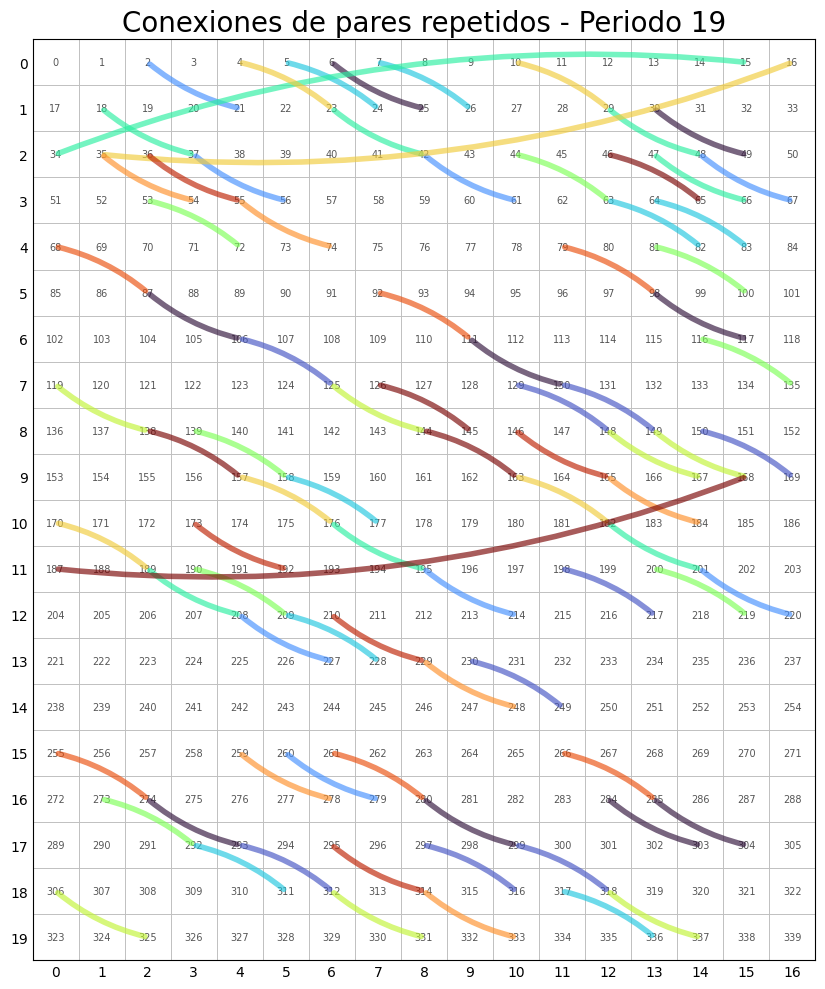

In [ ]:
#Función hecha con gran ayuda de IA y ajustada manualmente
def visualizar_conexiones(M, periodo=19, max_pares=12):

    C = ''.join(M.flatten())

    filas, columnas = M.shape

    pares = defaultdict(list)

    for i in range(len(C)-periodo):
        pares[(C[i], C[i+periodo])].append(i)

    pares_ordenados = sorted(
        [(p, pos) for p, pos in pares.items() if len(pos) >= 2],
        key=lambda x: len(x[1]),
        reverse=True
    )

    fig, ax = plt.subplots(figsize=(14, 10))


    ax.set_xlim(-0.5, columnas-0.5)
    ax.set_ylim(filas-0.5, -0.5)

    for r in range(filas):
        for c in range(columnas):
          # Poner #FFFFFF en ambos para que sea una cuadrícula blanca (para la presentación)

            color = "#FFFFFF" if (r+c) % 2 == 0 else "#FFFFFF"

            ax.add_patch(
                plt.Rectangle(
                    (c-0.5, r-0.5),
                    1, 1,
                    facecolor=color,
                    edgecolor="#bbbbbb",
                    linewidth=0.6
                )
            )

            posicion = r * columnas + c

            ax.text(
                c, r, str(posicion),
                ha="center",
                va="center",
                fontsize=7,
                color="#555555"
            )

    cantidad = min(max_pares, len(pares_ordenados))

    colores = plt.cm.turbo(np.linspace(0, 1, max(1, cantidad)))

    for k, (par, posiciones) in enumerate(pares_ordenados[:cantidad]):

        color = colores[k]

        for p in posiciones:

            r1, c1 = divmod(p, columnas)
            r2, c2 = divmod(p+periodo, columnas)

            conexion = FancyArrowPatch(
                (c1, r1),
                (c2, r2),
                connectionstyle=f"arc3,rad={0.12 if k%2==0 else -0.12}",
                arrowstyle="-",
                color=color,
                linewidth=4,
                alpha=0.65,
                zorder=3
            )

            ax.add_patch(conexion)

    ax.set_title(
        f"Conexiones de pares repetidos - Periodo {periodo}",
        fontsize=20
    )

    ax.set_xticks(range(columnas))
    ax.set_yticks(range(filas))

    ax.set_aspect("equal")
    ax.tick_params(length=0)

    fig.savefig("Conexiones_de_pares_repetidos.jpg")

    plt.tight_layout()
    plt.show()
#Fin creacion por IA

visualizar_conexiones(M, periodo=19, max_pares=12)

In [ ]:
def lectura_modular(M, a, b, inicio=(0, 0)):
    filas, columnas = M.shape
    i0, j0 = inicio

    return ''.join(
        str(M[(i0 + a*t) % filas,
              (j0 + b*t) % columnas])
        for t in range(filas * columnas)
    )


def evaluar_lectura(texto):
    bigramas = Counter(
        (texto[i], texto[i+1])
        for i in range(len(texto) - 1)
    )

    score_1 = sum(
        f - 1 for f in bigramas.values()
    )


    return {
        "score_1": score_1,
        "bigramas_distintos": len(bigramas),
        "frecuencias": bigramas
    }


def buscar_lecturas_modulares(
    M,
    top_k=5,
    inicio=(0, 0),
    todos_los_inicios=False
):
    A = (1, 3, 7, 9, 11, 13, 17, 19)
    B = tuple(range(1, 17))

    DECIMACIONES = [(a, b) for a in A for b in B]
    M = np.asarray(M, dtype=object)
    filas, columnas = M.shape

    if (filas, columnas) != (20, 17):
        raise ValueError(
            "Este código está configurado para matrices 20x17."
        )

    inicios = (
        [(i, j) for i in range(filas)
                for j in range(columnas)]
        if todos_los_inicios
        else [inicio]
    )

    resultados = []

    for a, b in DECIMACIONES:
        for punto_inicial in inicios:

            texto = lectura_modular(
                M, a, b, punto_inicial
            )

            evaluacion = evaluar_lectura(texto)

            resultados.append({
                "a": a,
                "b": b,
                "inicio": punto_inicial,
                "score_1": evaluacion["score_1"],
                "texto": texto,
                "frecuencias": evaluacion["frecuencias"]
            })

    resultados.sort(
        key=lambda x: (x["score_1"],),
        reverse=True
    )

    return resultados[:top_k]


resultados = buscar_lecturas_modulares(M, top_k=5)

for k, r in enumerate(resultados, 1):
    print(f"\nCandidato {k}")
    print(f"Decimación: ({r['a']}, {r['b']})")
    print(f"Puntaje: {r['score_1']}")
    print(f"Texto: {r['texto']}")


Candidato 1
Decimación: (1, 2)
Puntaje: 181
Texto: ⍙⎈◬⍎⎈⏃⏈⍕⍖⍎◬⏃⍤⎈⍎⍕⍖⏈⎋⏈⍘⎈⍛⏈⍗⎍⏃⏈⍙⍖⎅⎈⍎⍗⎋⎈⍕◬⏃⌖⍕⏈⌖⏈☊◬⍜⍗⎋⎋⟁⏈⏁⏁☊⍖⏁⎈⏃⍖☊⍕⍙⎅◬⍖☊◬⏁⍖⎅☊⏃⎍☊⏃⍤⏈⍜⍛⏈⍗⍙⏈⍗⎋⌖⏃⏈⍖⍤⎈⍖⍖⎅☊⍕⍜⍎⏈⏁◬⏃⍛⏈⍖⎅⎈⍎⍤⍗⍛☊⌕⍗⍕⍖⍙◬⏃⏃◬⍖⎈⎋⎋⍛⏈⍗⎅⏈⍙☊◬⏁⍜⎈⎈⎋☊⏃⍤⍤⏈⍖⍖◬⏁◬⎍⎈⍛⏈⍗⍗⏃⌖⎈⍎⍕⍖◬⏃⌖⏃⎈⍘⎈⍎⍤⏈⏃⏃◬⍤☊⍘⎈⍛⏈⍗⍗⌰⏃⎈⍘⎈⍎⍤⏈⏃⏃◬⎋⎈⍖⍛⏈⍗⌖⏈⍙⏃⏃⎈⍘⎈⍎⍤⏈⏃⏃◬⍎⍗⏃◬⍎⏈⍗⏃⌖◬⏃⌖⌖⎈⍕⎈⍎⍖⍛⏈⍗⏃⎈⍘⎈⍎⍤⏈⏃⏃◬⏁◬⎍⎈⍛⏈⍗⟁⍎⍛⏃⎈⍘⎈⍎⍤⏈⏃⏃◬⍕◬⍛⍤⏈⏈⌖◫⍛⎈⏃⎈⍘⎈⍎⍤⏈⏃⏃◬⍖⎈⎋⎋◬⎋☊⎈◬⏃⌖⎅⍗⍎⍖⍛⏈⍗☊⍜⍛⏈⍗⎋◬⍗⍤⎅⎈⌖⍖⎅⎈⏃⎋⎈◬⍘⎈◬⎋☊⎍⎈◬⏃⌖⍕⍗◫⍕⟁⍎☊◫⎈

Candidato 2
Decimación: (19, 15)
Puntaje: 181
Texto: ⍙⎈◫☊⍎⟁⍕◫⍗⍕⌖⏃◬⎈⎍☊⎋◬⎈⍘◬⎈⎋⏃⎈⎅⍖⌖⎈⎅⍤⍗◬⎋⍗⏈⍛⍜☊⍗⏈⍛⍖⍎⍗⎅⌖⏃◬⎈☊⎋◬⎋⎋⎈⍖◬⏃⏃⏈⍤⍎⎈⍘⎈⏃⎈⍛◫⌖⏈⏈⍤⍛◬⍕◬⏃⏃⏈⍤⍎⎈⍘⎈⏃⍛⍎⟁⍗⏈⍛⎈⎍◬⏁◬⏃⏃⏈⍤⍎⎈⍘⎈⏃⍗⏈⍛⍖⍎⎈⍕⎈⌖⌖⏃◬⌖⏃⍗⏈⍎◬⏃⍗⍎◬⏃⏃⏈⍤⍎⎈⍘⎈⏃⏃⍙⏈⌖⍗⏈⍛⍖⎈⎋◬⏃⏃⏈⍤⍎⎈⍘⎈⏃⌰⍗⍗⏈⍛⎈⍘☊⍤◬⏃⏃⏈⍤⍎⎈⍘⎈⏃⌖⏃◬⍖⍕⍎⎈⌖⏃⍗⍗⏈⍛⎈⎍◬⏁◬⍖⍖⏈⍤⍤⏃☊⎋⎈⎈⍜⏁◬☊⍙⏈⎅⍗⏈⍛⎋⎋⎈⍖◬⏃⏃◬⍙⍖⍕⍗⌕☊⍛⍗⍤⍎⎈⎅⍖⏈⍛⏃◬⏁⏈⍎⍜⍕☊⎅⍖⍖⎈⍤⍖⏈⏃⌖⎋⍗⏈⍙⍗⏈⍛⍜⏈⍤⏃☊⎍⏃☊⎅⍖⏁◬☊⍖◬⎅⍙⍕☊⍖⏃⎈⏁⍖☊⏁⏁⏈⟁⎋⎋⍗⍜◬☊⏈⌖⏈⍕⌖⏃◬⍕⎈⎋⍗⍎⎈⎅⍖⍙⏈⏃⎍⍗⏈⍛⎈⍘⏈⎋⏈⍖⍕⍎⎈⍤⏃◬⍎⍖⍕⏈⏃⎈⍎◬⎈

Candidato 3
Decimación: (3, 6)
Puntaje: 158
Texto: ⍙⍎⏈⍎⍤⍕⎋⎈⍗⏈⎅⍗⍕⌖⌖◬⎋⏈☊⎈☊⎅☊⍖⏃⏃⍜⍗⍗⏃⍤⍖⍕⏈⏃⍖⍎⍛⍗⍙⏃⎈⍛⎅☊⍜⎋⍤⍖⏁⎈⍗⌖⍕⏃⎈⍎⏃⍤⎈⍗⏃⎈⏈◬⍖⍗⍙⎈⍎⏃⍎◬⍗◬⌖⎈⍛⏃⎈⏈◬⎍⏈⍎⎈⍎⏃⍕⍤⌖⎈⍘⍤⏃⎈◬⎈⌖⍎⏈⍜⍗⍗⎈⎅⎋⍘⎋⎈⌖◫⍎⎈◬⏃⍖⏃⍎⏈⍘⏈⏃⍖⍎⎈⏃⏈☊⍗⟁⏁⏁⍖⍙⍖⏁☊☊⏈⏈⏈⌖⍖⍖☊⍎◬⏈⎈⍗⌕⍖⏃⍖⎋⍗⍙⏁⎈

## Visualización de los recorrdios por decimación

Los códigos que siguen están más pensados para la presentación, la idea es presentar ejemplos de algunas de las lecturas diagonales que vamos a utilizar

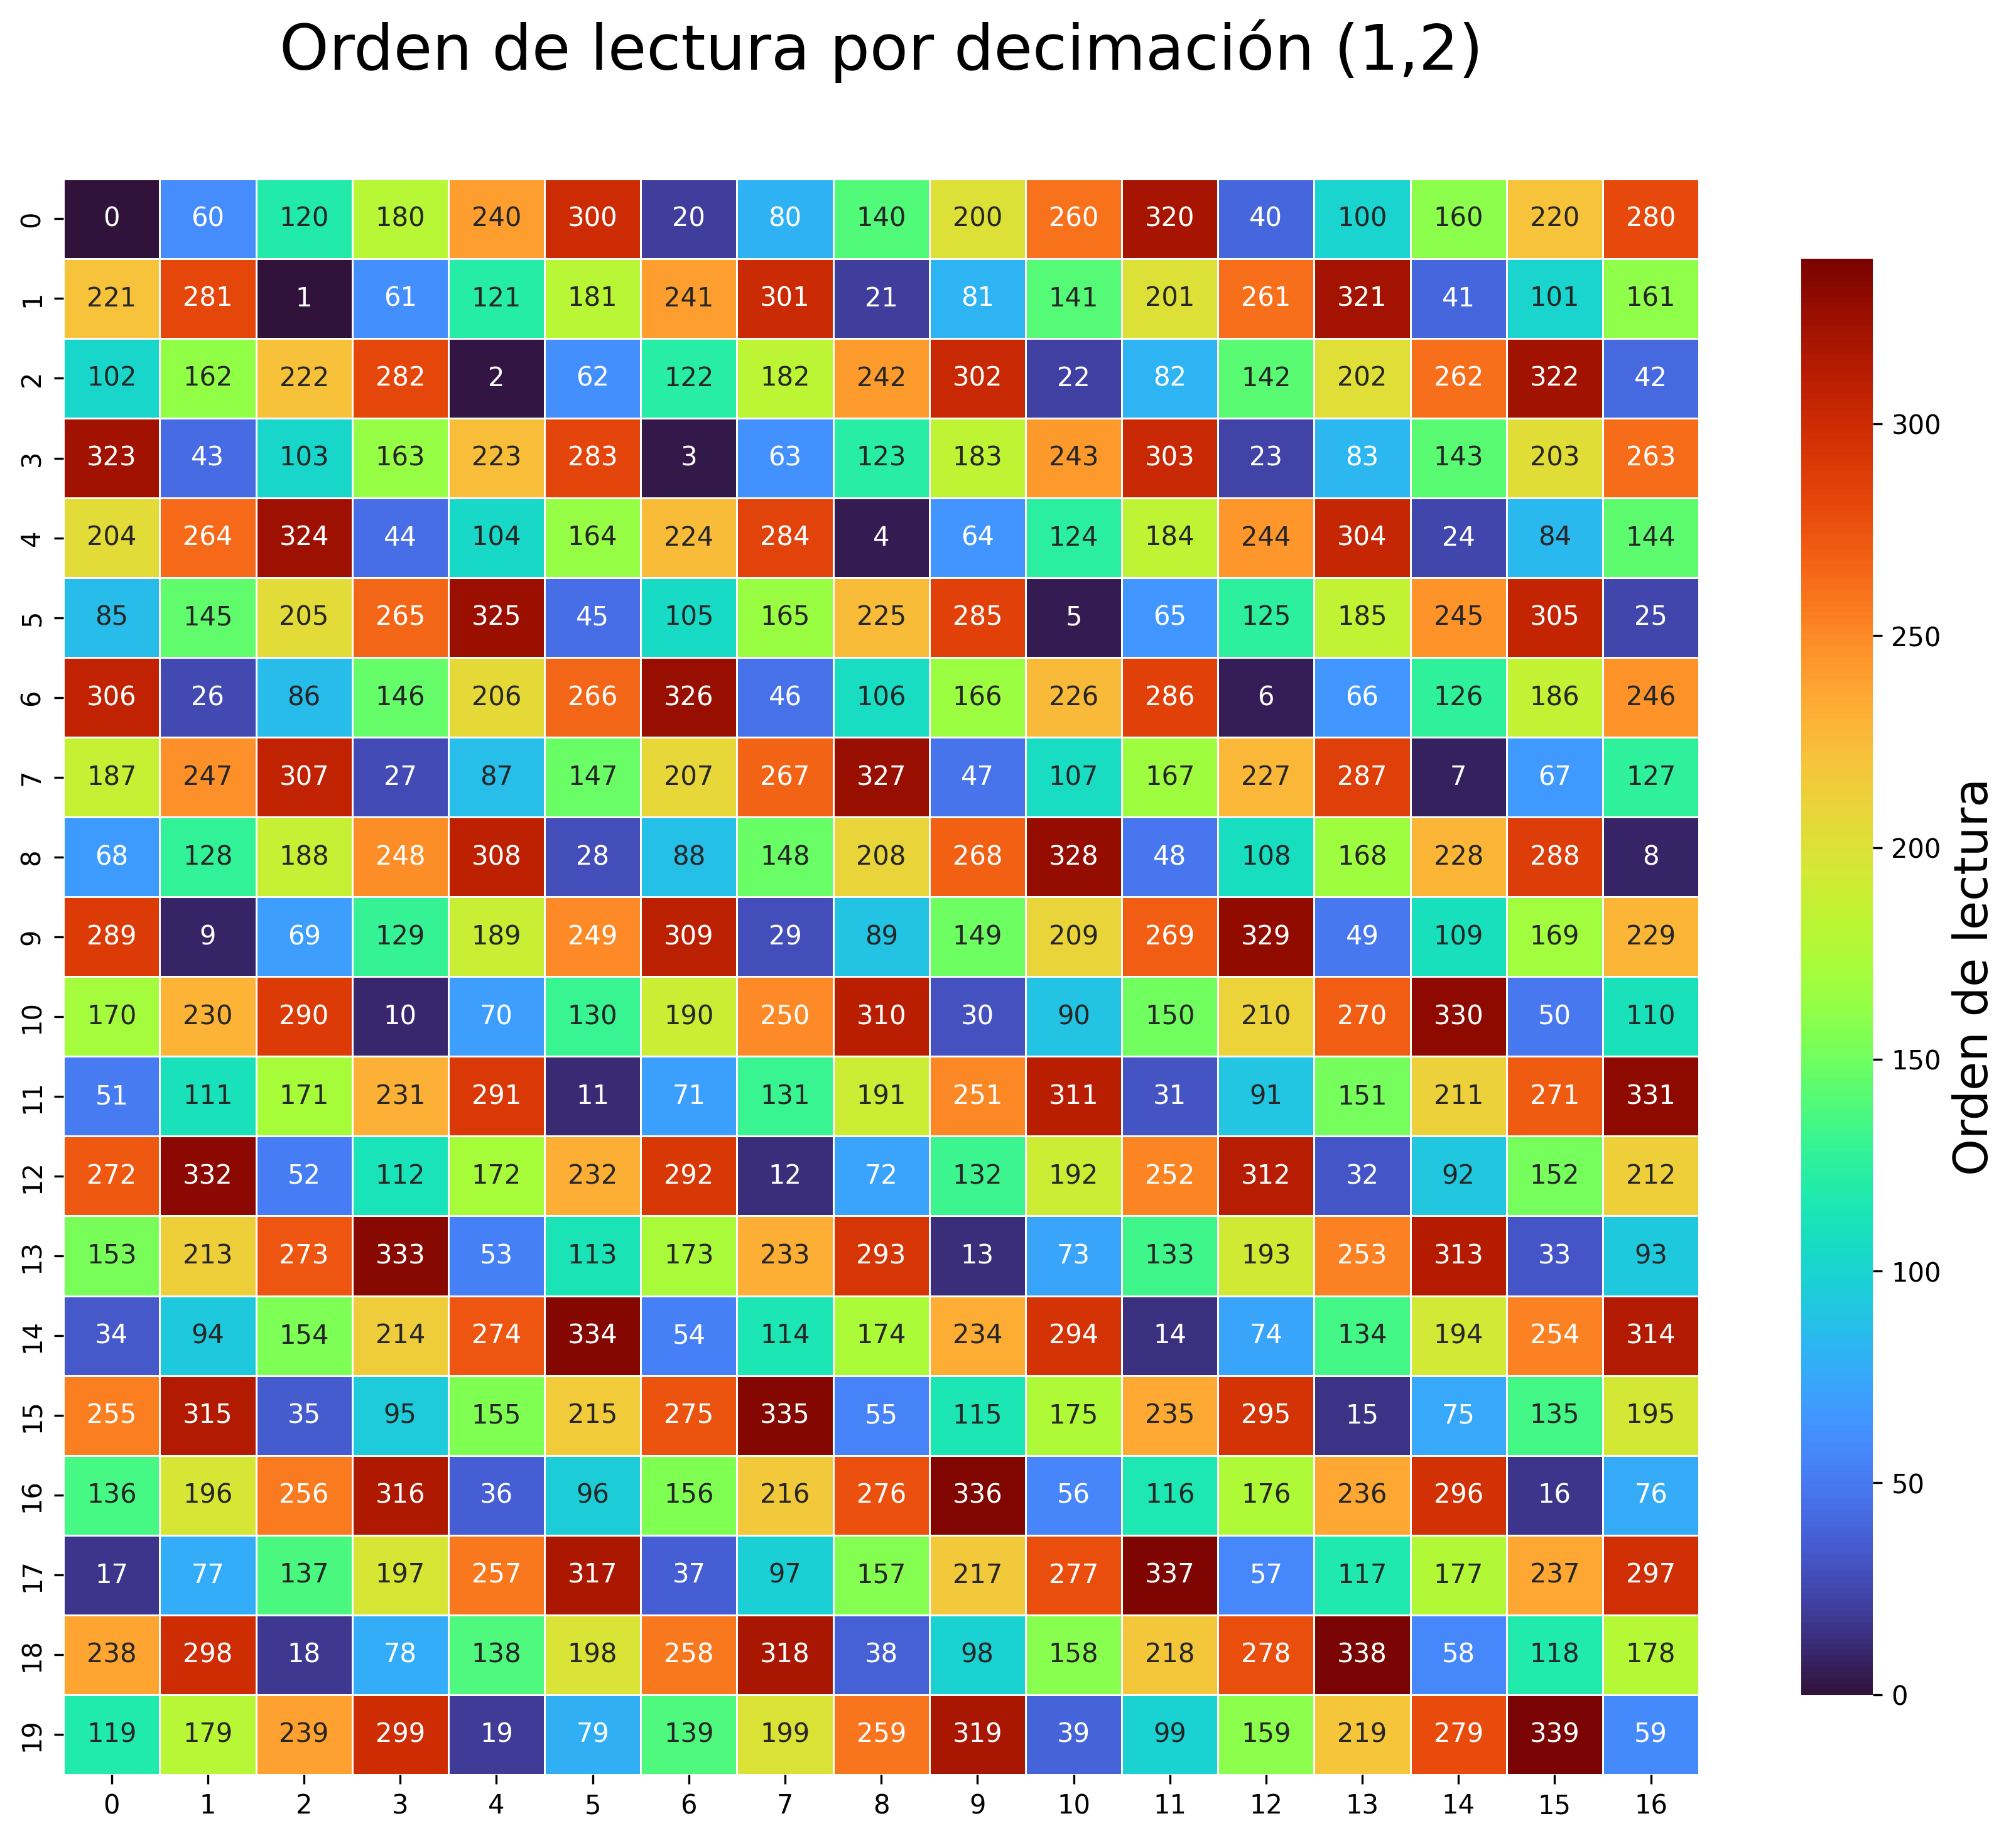

<Figure size 640x480 with 0 Axes>

In [ ]:
#Esta función fue generada con IA y modificada manualmente
def visualizar_decimacion(df=1, dc=2, filas=20, columnas=17):

    n = filas * columnas

    # Matriz que almacena el orden de lectura
    orden = np.zeros((filas, columnas), dtype=int)

    for k in range(n):
        i = (df * k) % filas
        j = (dc * k) % columnas

        orden[i, j] = k

    # Crear figura
    plt.figure(figsize=(14, 11), dpi=300)

    ax = sns.heatmap(
        orden,
        cmap='turbo',
        annot=True,
        fmt='d',
        linewidths=0.3,
        linecolor='white',
        cbar_kws={
            'label': 'Orden de lectura',
            'shrink': 0.9
        },
        norm=Normalize(vmin=0, vmax=n-1),
        annot_kws={'size': 10}
    )
    cbar = ax.collections[0].colorbar
    cbar.set_label('Orden de lectura', fontsize=18)

    ax.set_title(
        f"Orden de lectura por decimación ({df},{dc})\n",
        fontsize=24,
        pad=15
    )

    #ax.set_xlabel("Columna")
    #ax.set_ylabel("Fila")

    plt.savefig("Orden_de_lectora_por_decimacion.jpg", dpi=300, bbox_inches='tight')

    plt.show()

    plt.tight_layout()
    plt.show()
#Fin código generado con IA

# Ejemplo
visualizar_decimacion(df=1, dc=2)

## Aplicando los algoritmos

### Esquema geométrico

Evaluando decimación (1,2)...


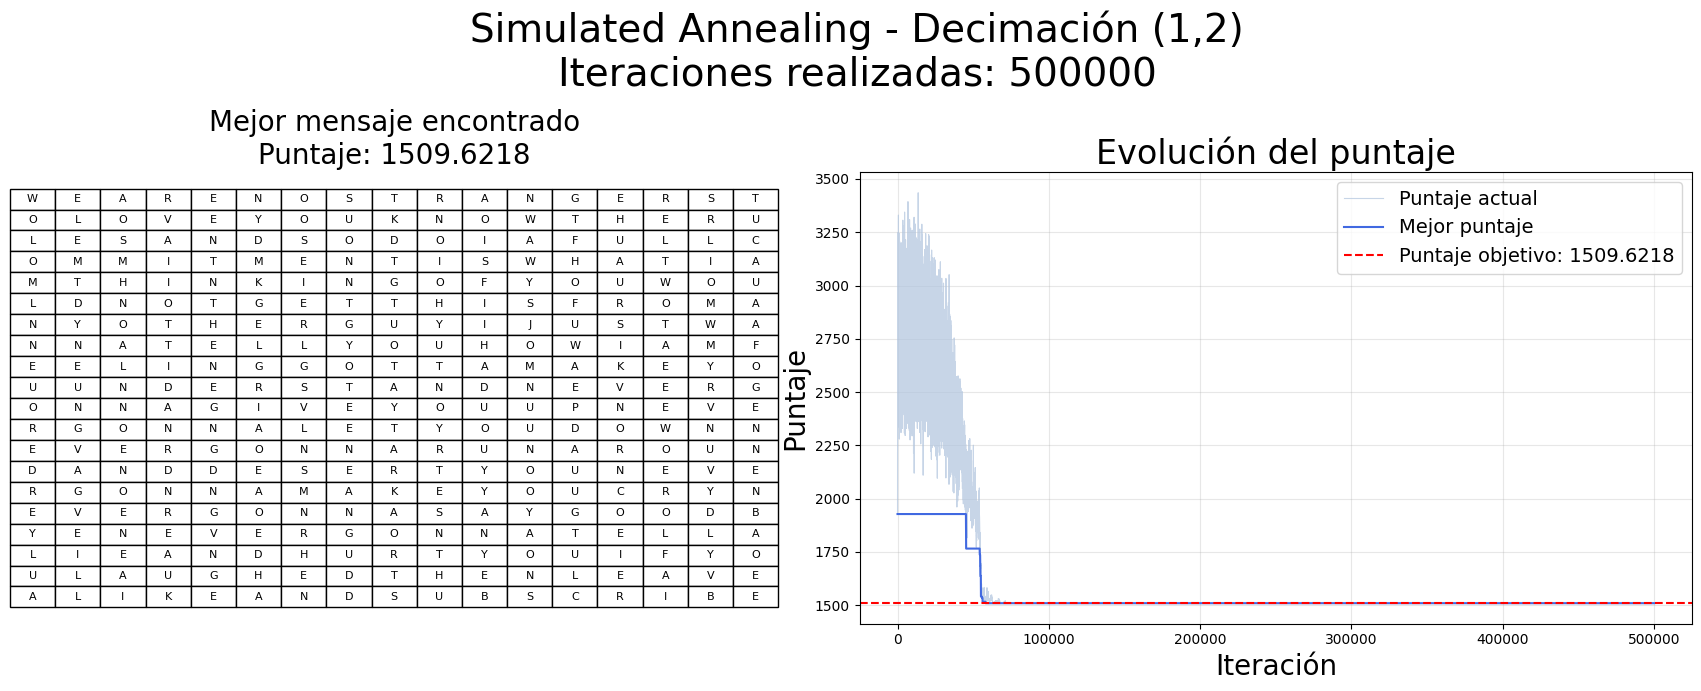

Evaluando decimación (19,15)...


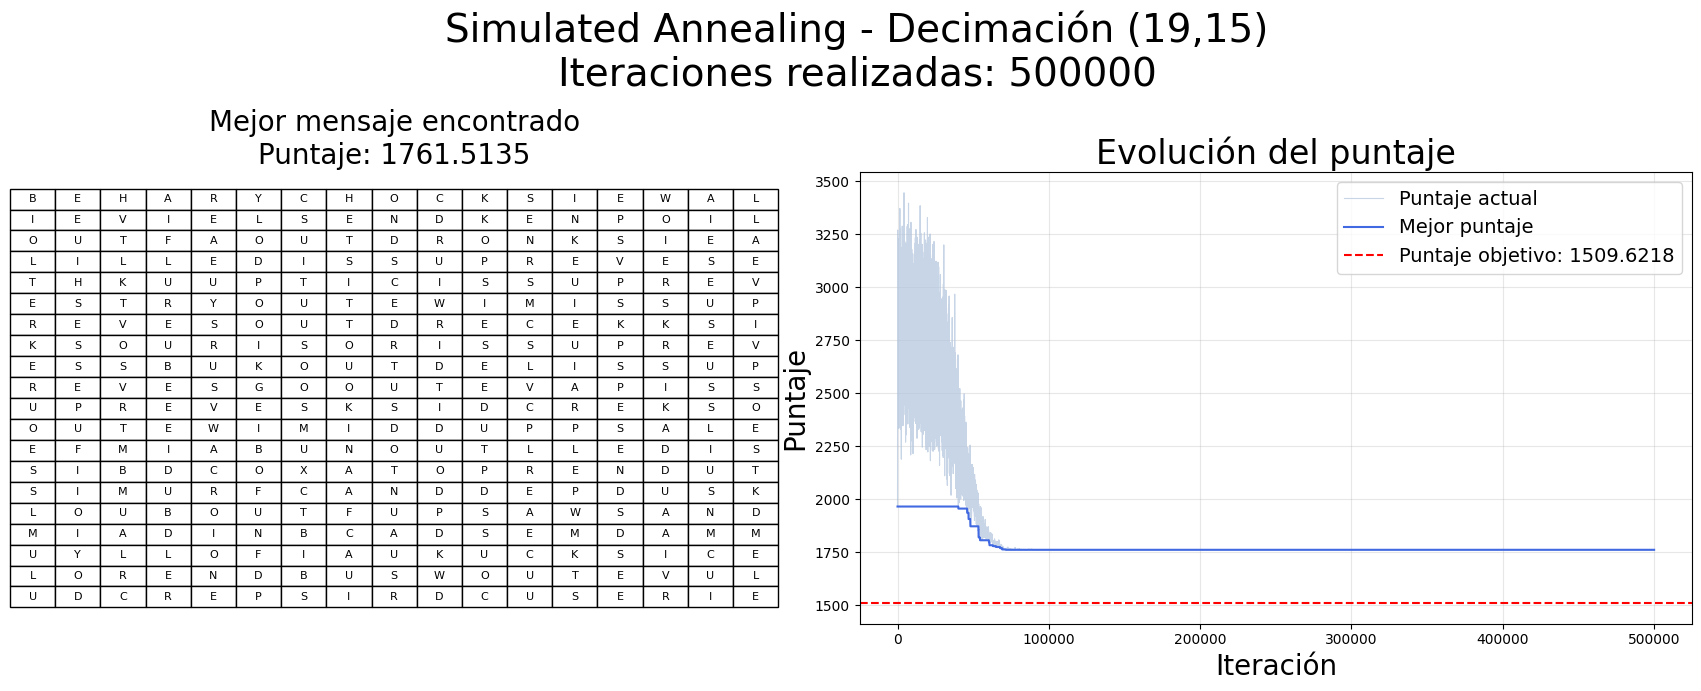

Evaluando decimación (3,6)...


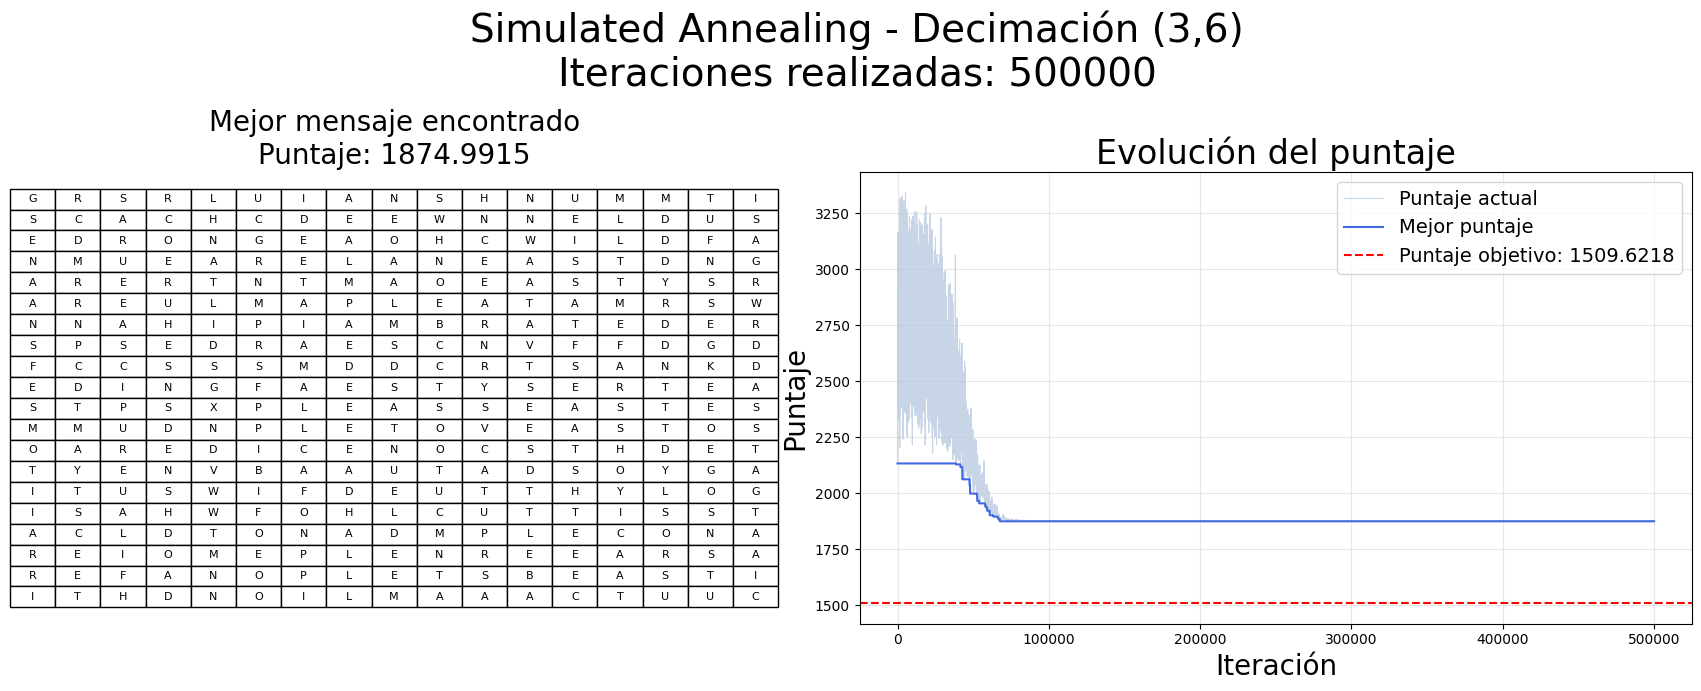

Evaluando decimación (17,11)...


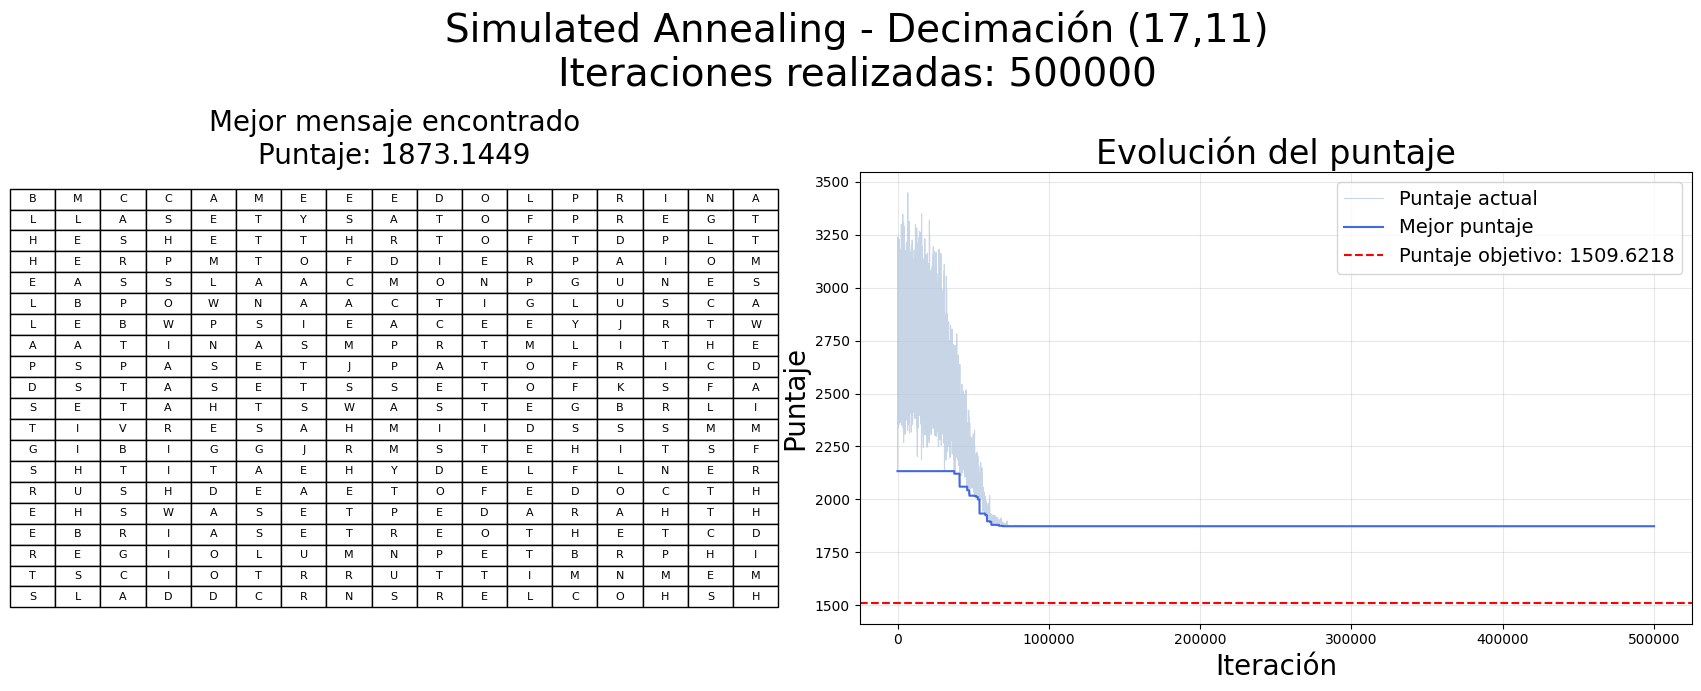

Evaluando decimación (7,2)...


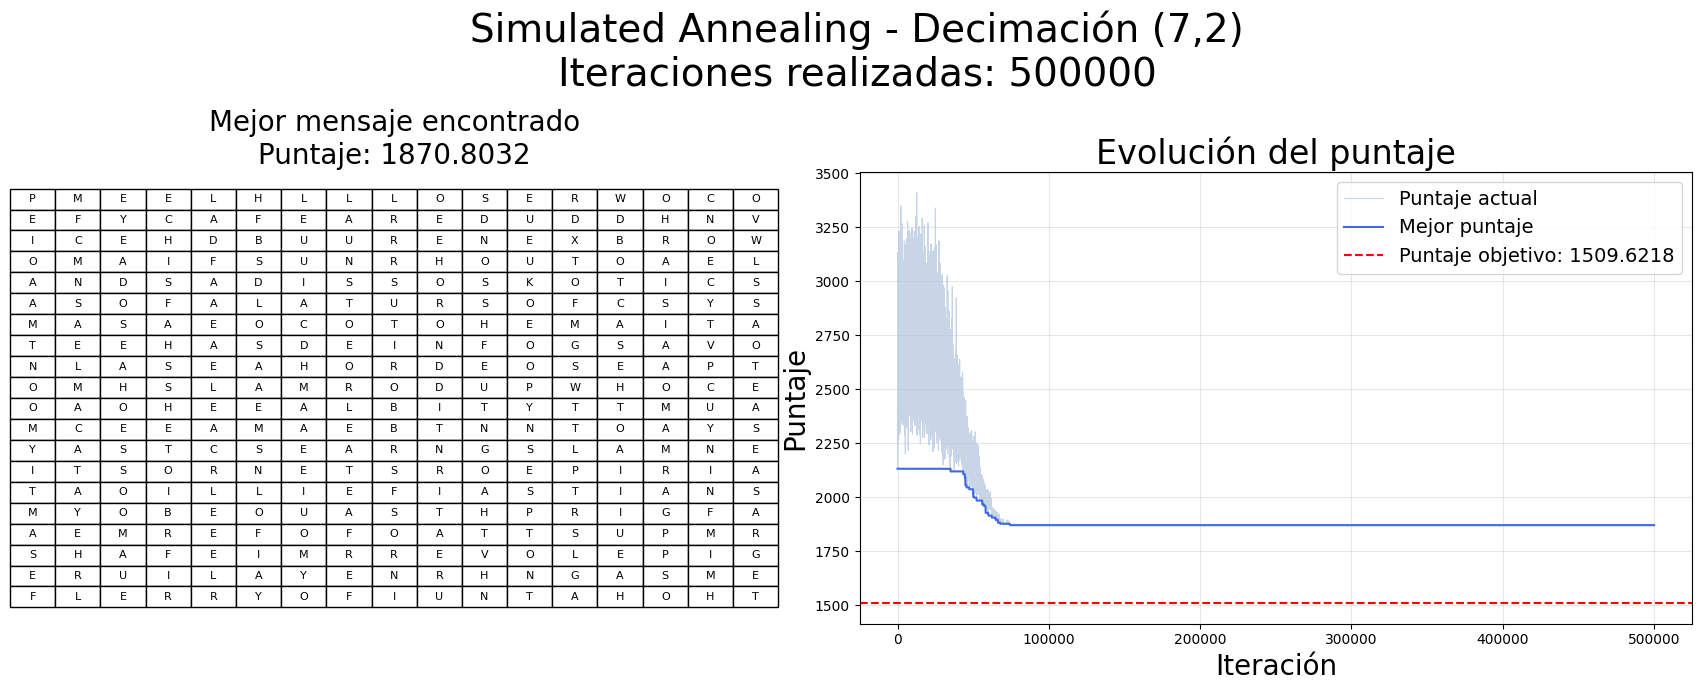

In [ ]:
mejores_decimaciones = [(1, 2), (19, 15), (3 ,6), (17, 11), (7, 2)]

resultados_SA = []

for a, b in mejores_decimaciones:

    print(f"Evaluando decimación ({a},{b})...")

    resultado = SimulatedAnnealing_decimaciones(
        M,
        lista_caract,
        df=a,
        dc=b,
        Tiempo=500000,
        M_objetivo=M_original,
        T0 = 2500
    )

    resultados_SA.append({
        "decimacion": (a, b),
        "mensaje": resultado[0],
        "sigma": resultado[1],
        "matriz": resultado[2]
    })

--- Paso 1.000000e+06 | Temperatura: 3.701521e-42 ---
Mejor Funcion (Energía/Puntaje): 1271.7239730833057
Mejor Matriz M:
 [['L' 'Y' 'T' 'H' 'A' 'V' 'E' 'N' 'T' 'I' 'N' 'G' 'I' 'N' 'C' 'O' 'N']
 ['O' 'F' 'C' 'O' 'M' 'E' 'F' 'O' 'R' 'A' 'N' 'D' 'A' 'N' 'D' 'I' 'N']
 ['T' 'H' 'A' 'T' 'T' 'H' 'E' 'R' 'W' 'A' 'S' 'T' 'I' 'L' 'L' 'I' 'T']
 ['Y' 'T' 'H' 'E' 'S' 'T' 'A' 'T' 'E' 'R' 'I' 'V' 'E' 'B' 'U' 'T' 'T']
 ['H' 'E' 'S' 'T' 'H' 'E' 'C' 'A' 'L' 'A' 'N' 'D' 'I' 'N' 'C' 'L' 'U']
 ['D' 'E' 'A' 'N' 'D' 'F' 'O' 'R' 'T' 'H' 'A' 'N' 'D' 'F' 'O' 'R' 'M']
 ['O' 'S' 'T' 'U' 'D' 'E' 'D' 'A' 'N' 'D' 'I' 'C' 'A' 'T' 'E' 'D' 'T']
 ['H' 'E' 'R' 'W' 'A' 'Y' 'O' 'F' 'A' 'M' 'O' 'U' 'T' 'I' 'O' 'N' 'S']
 ['T' 'H' 'E' 'A' 'V' 'E' 'I' 'T' 'W' 'A' 'S' 'C' 'O' 'M' 'I' 'L' 'Y']
 ['B' 'Y' 'A' 'B' 'O' 'U' 'T' 'I' 'N' 'G' 'T' 'O' 'N' 'W' 'A' 'S' 'J']
 ['U' 'S' 'T' 'A' 'T' 'E' 'D' 'W' 'I' 'T' 'H' 'R' 'O' 'U' 'T' 'A' 'T']
 ['I' 'V' 'E' 'R' 'A' 'L' 'S' 'O' 'U' 'R' 'O' 'P' 'E' 'D' 'T' 'O' 'P']
 ['O' 'F' 'Y' 'O' 'U' 'T'

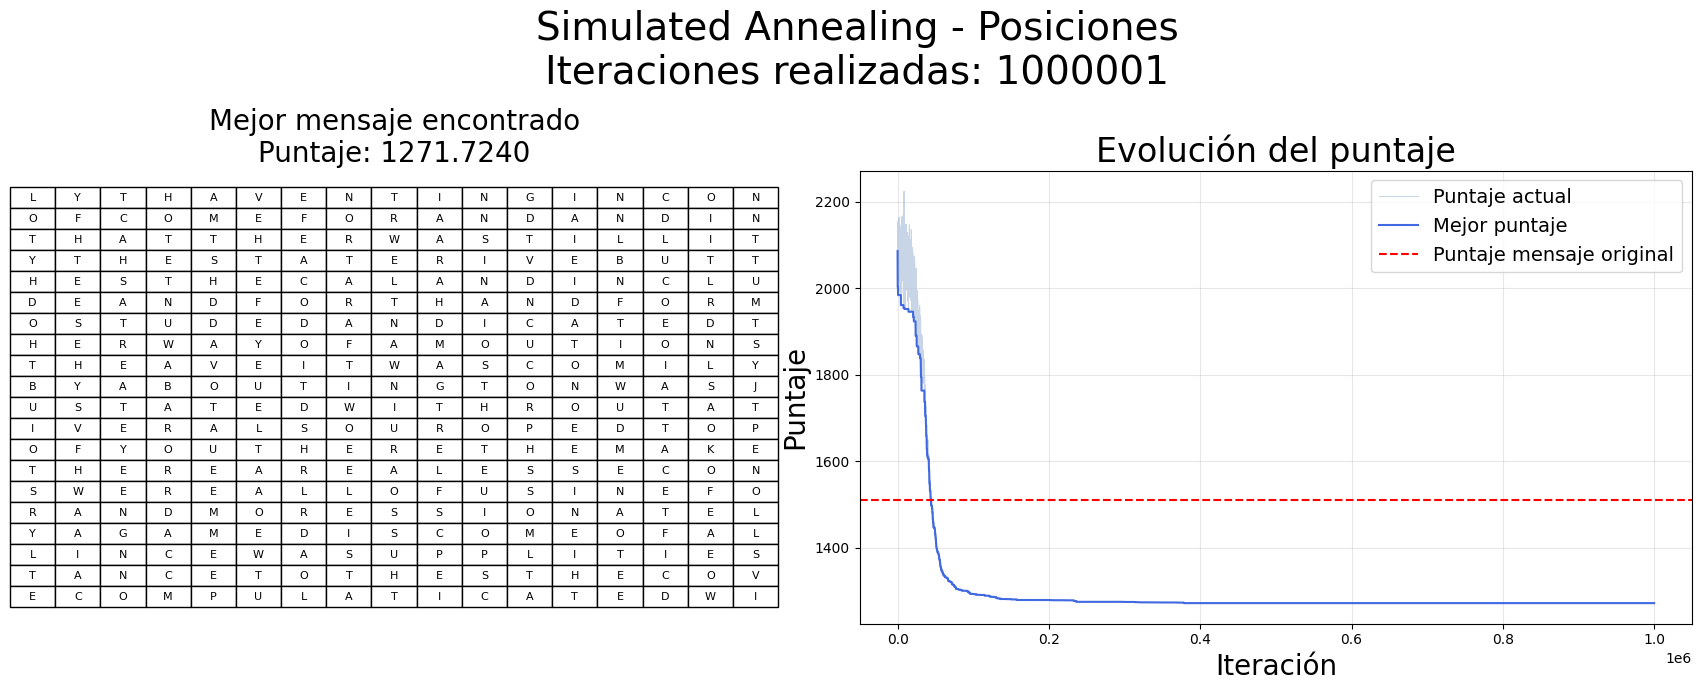

In [ ]:
mensaje, cuadricula = estimar_posiciones(M, lista_caract, Tiempo = 1e6, T_min=1e-80)

--- Paso 1.000000e+06 | Temperatura: 3.701521e-42 ---
Mejor Funtion (Energía/Puntaje): 1295.5066845222302
Mejor Matriz M:
 [['Z' 'B' 'U' 'T' 'H' 'A' 'T' 'H' 'E' 'R' 'E' 'D' 'T' 'H' 'E' 'R' 'S']
 ['O' 'F' 'F' 'I' 'N' 'C' 'T' 'I' 'V' 'E' 'R' 'T' 'I' 'C' 'A' 'N' 'D']
 ['C' 'O' 'M' 'E' 'A' 'S' 'A' 'L' 'S' 'C' 'O' 'N' 'T' 'H' 'I' 'G' 'H']
 ['T' 'H' 'A' 'V' 'E' 'P' 'R' 'O' 'M' 'P' 'A' 'R' 'T' 'H' 'E' 'S' 'T']
 ['O' 'S' 'P' 'I' 'T' 'C' 'A' 'L' 'C' 'O' 'M' 'P' 'L' 'A' 'N' 'D' 'S']
 ['C' 'O' 'N' 'T' 'H' 'E' 'S' 'T' 'O' 'F' 'F' 'I' 'C' 'A' 'M' 'P' 'A']
 ['R' 'T' 'S' 'A' 'N' 'D' 'S' 'T' 'O' 'R' 'S' 'A' 'B' 'O' 'U' 'T' 'O']
 ['F' 'C' 'O' 'M' 'P' 'L' 'A' 'C' 'T' 'I' 'N' 'G' 'T' 'O' 'B' 'E' 'C']
 ['O' 'M' 'P' 'A' 'N' 'D' 'T' 'H' 'A' 'T' 'H' 'E' 'A' 'B' 'L' 'Y' 'C']
 ['O' 'M' 'P' 'A' 'R' 'T' 'W' 'A' 'S' 'C' 'O' 'M' 'B' 'E' 'R' 'S' 'W']
 ['A' 'S' 'I' 'S' 'T' 'R' 'A' 'N' 'D' 'I' 'S' 'C' 'O' 'V' 'E' 'R' 'A']
 ['S' 'T' 'O' 'P' 'L' 'E' 'X' 'P' 'L' 'O' 'S' 'E' 'C' 'O' 'M' 'P' 'A']
 ['R' 'A' 'C' 'T' 'O' 'R'

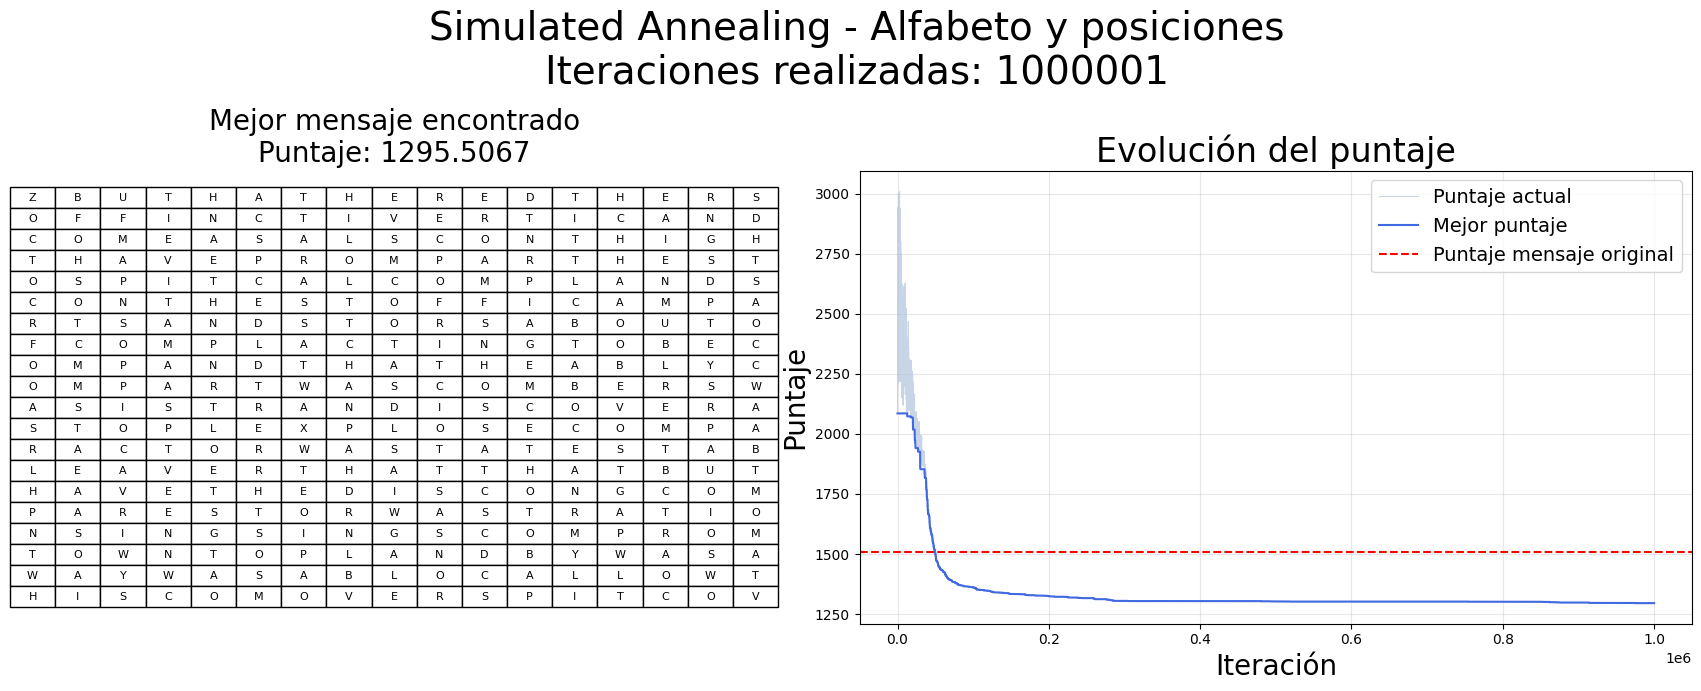

In [ ]:
mensaje, alfabeto, cuadricula = estimar_alfabeto_posiciones(M, lista_caract, Tiempo = 1e6, T_min=1e-80)

### Esquema lineal

Evaluando decimación (1,2)...


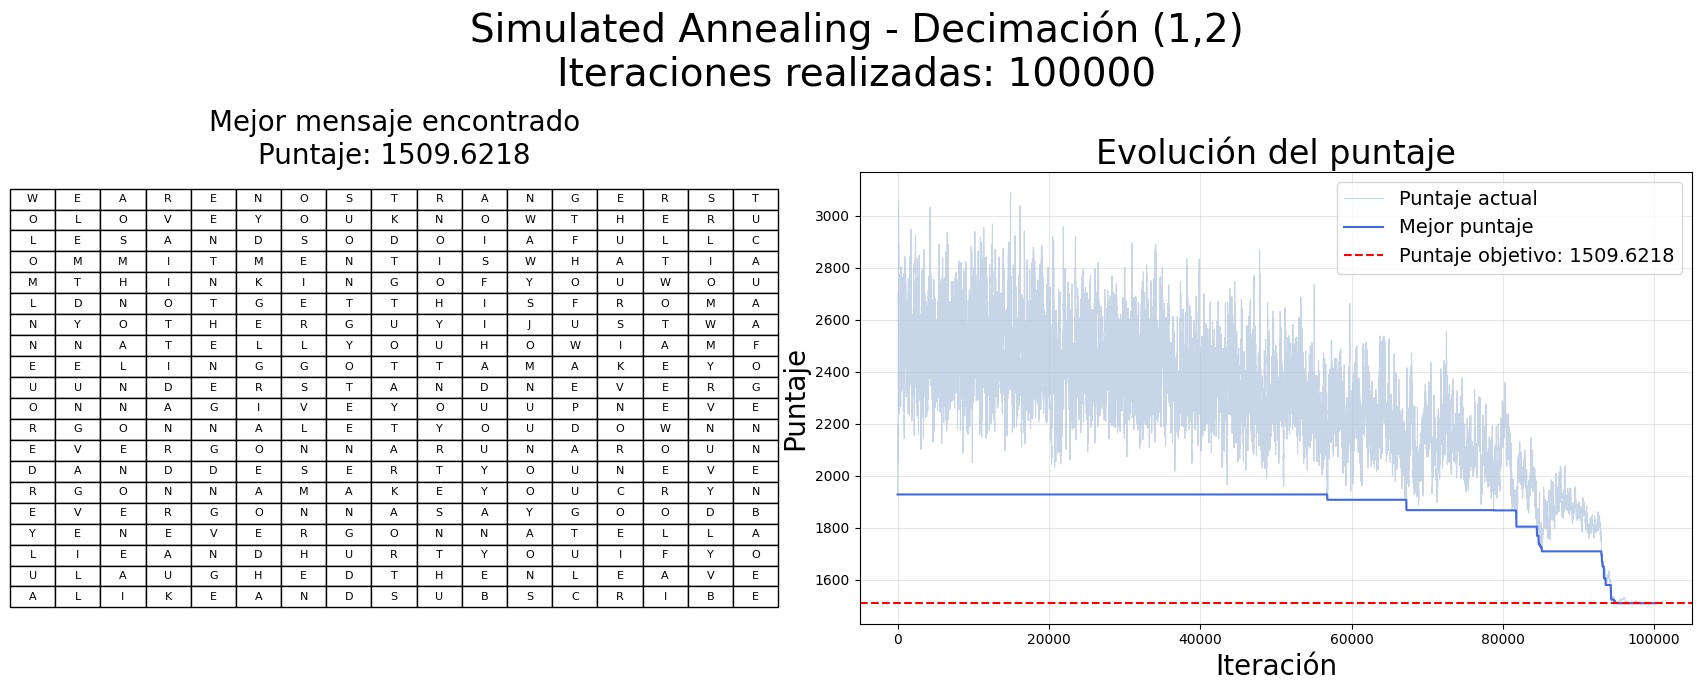

Evaluando decimación (19,15)...


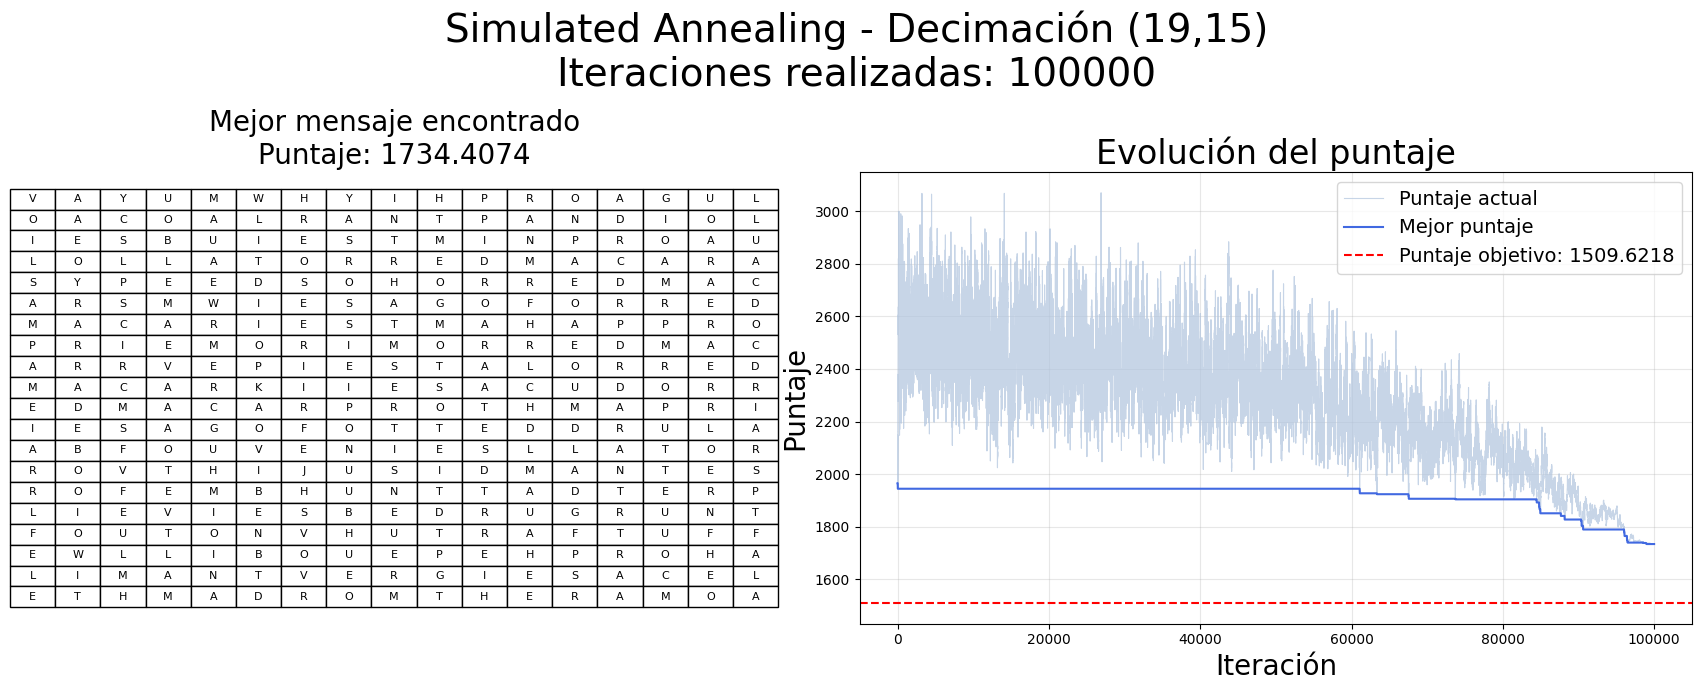

Evaluando decimación (3,6)...


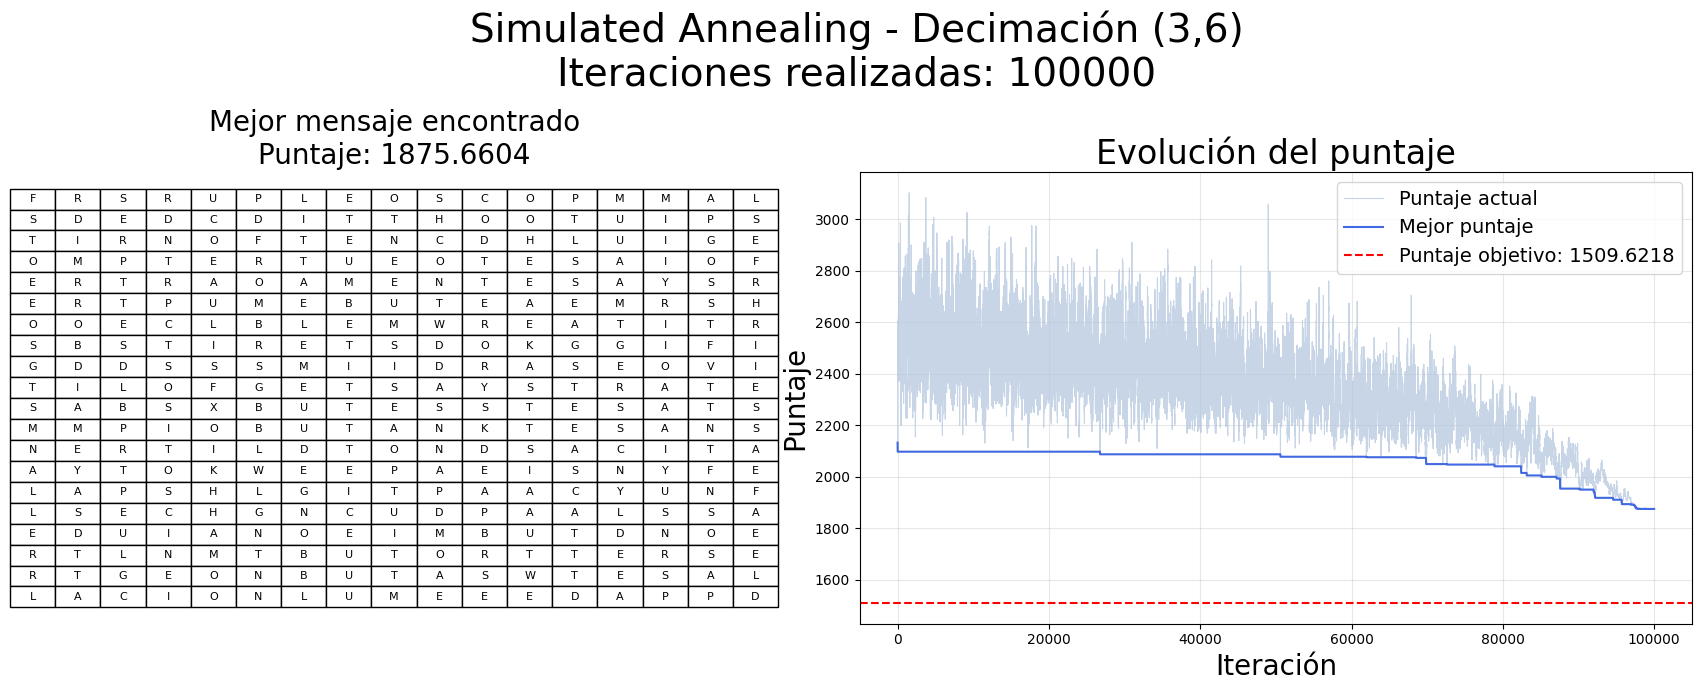

Evaluando decimación (17,11)...


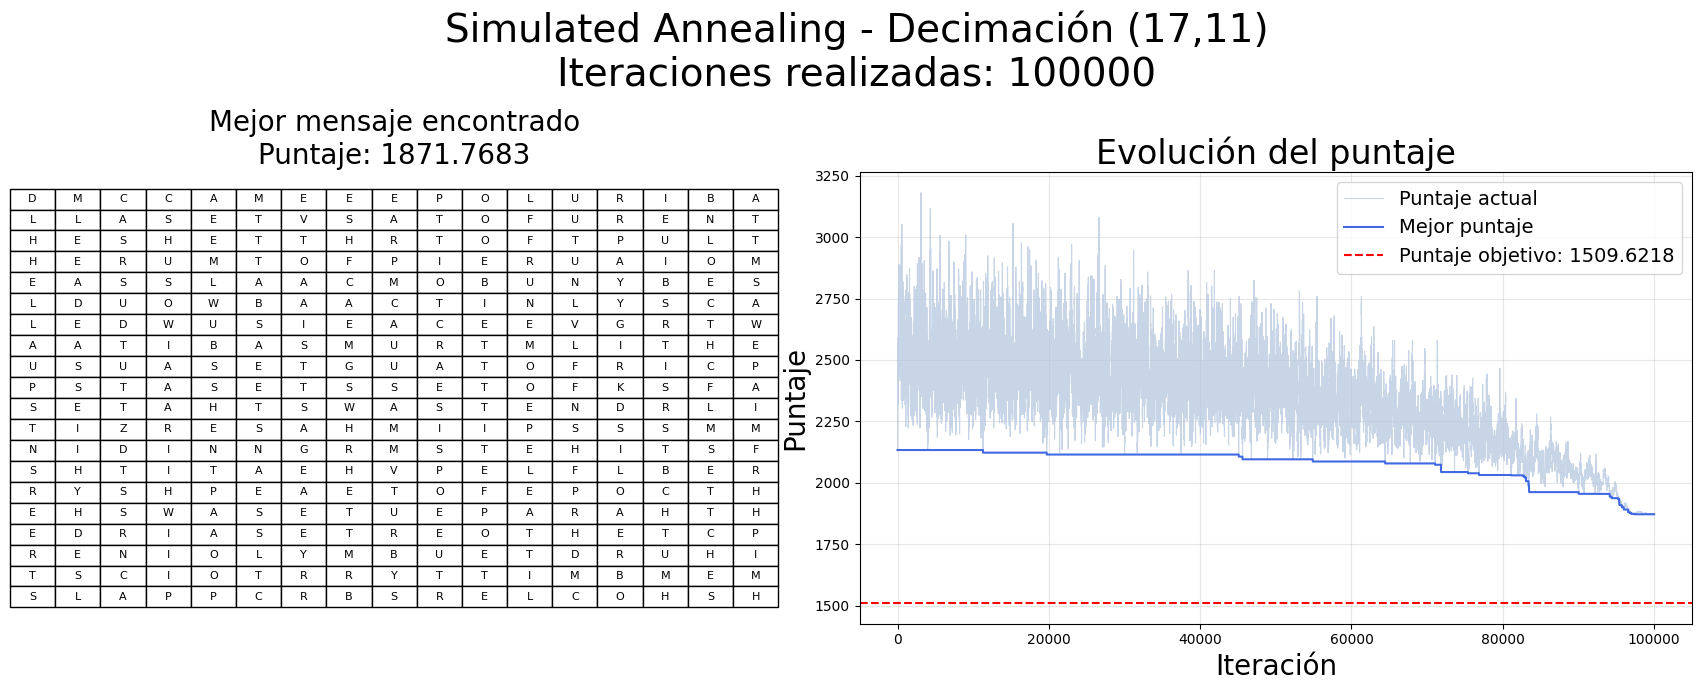

Evaluando decimación (7,2)...


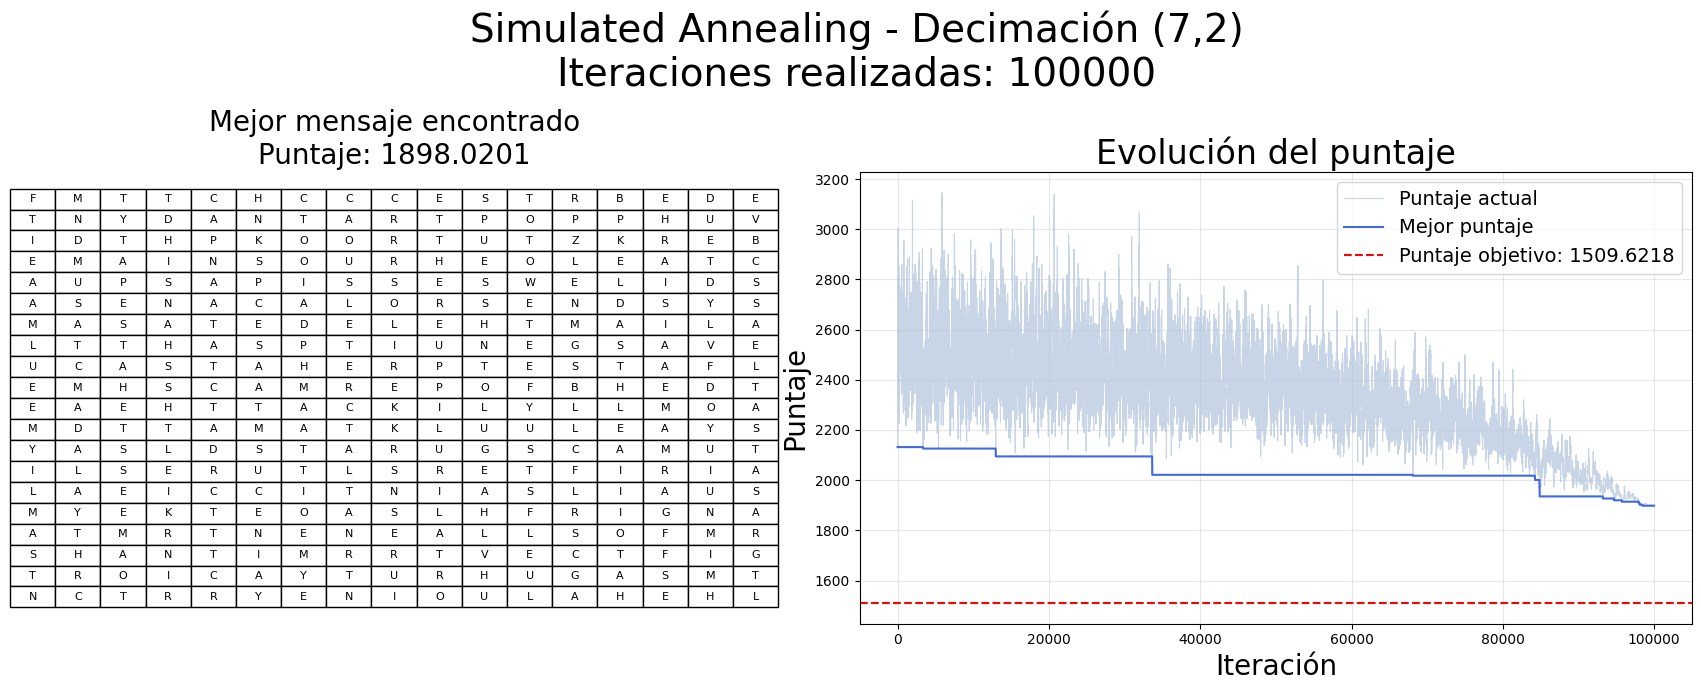

In [ ]:
mejores_decimaciones = [(1, 2), (19, 15), (3 ,6), (17, 11), (7, 2)]

resultados_SA = []

for a, b in mejores_decimaciones:

    print(f"Evaluando decimación ({a},{b})...")

    resultado = SimulatedAnnealing_decimaciones(
        M,
        lista_caract,
        df = a,
        dc = b,
        Tiempo = 1e6,
        M_objetivo = M_original,
        esquema = "lineal"
    )

    resultados_SA.append({
        "decimacion": (a, b),
        "mensaje": resultado[0],
        "sigma": resultado[1],
        "matriz": resultado[2]
    })

--- Paso 1.000000e+06 | Temperatura: 1.000000e-80 ---
Mejor Funcion (Energía/Puntaje): 1282.3547436978379
Mejor Matriz M:
 [['F' 'T' 'H' 'E' 'Y' 'R' 'E' 'M' 'O' 'S' 'T' 'O' 'U' 'S' 'I' 'C' 'A']
 ['L' 'J' 'U' 'S' 'T' 'I' 'M' 'E' 'N' 'T' 'H' 'O' 'U' 'T' 'O' 'F' 'F']
 ['E' 'R' 'E' 'A' 'S' 'T' 'E' 'D' 'I' 'N' 'G' 'O' 'U' 'T' 'A' 'B' 'O']
 ['U' 'T' 'T' 'H' 'E' 'R' 'M' 'A' 'I' 'N' 'T' 'H' 'A' 'V' 'E' 'T' 'H']
 ['E' 'O' 'P' 'L' 'E' 'W' 'A' 'S' 'T' 'H' 'A' 'T' 'W' 'I' 'C' 'E' 'T']
 ['O' 'A' 'C' 'C' 'O' 'U' 'S' 'E' 'O' 'F' 'O' 'R' 'A' 'C' 'T' 'U' 'R']
 ['E' 'A' 'C' 'C' 'U' 'S' 'T' 'A' 'T' 'E' 'L' 'Y' 'B' 'E' 'A' 'T' 'E']
 ['R' 'V' 'E' 'R' 'E' 'A' 'L' 'M' 'A' 'N' 'Y' 'S' 'T' 'A' 'N' 'D' 'I']
 ['N' 'G' 'F' 'O' 'L' 'L' 'O' 'V' 'E' 'R' 'O' 'F' 'T' 'H' 'E' 'F' 'R']
 ['A' 'N' 'D' 'H' 'I' 'S' 'W' 'E' 'R' 'E' 'A' 'L' 'L' 'I' 'N' 'T' 'O']
 ['F' 'D' 'I' 'V' 'I' 'D' 'E' 'N' 'T' 'O' 'M' 'A' 'T' 'E' 'D' 'T' 'O']
 ['G' 'E' 'T' 'I' 'M' 'A' 'T' 'I' 'V' 'E' 'D' 'T' 'H' 'E' 'D' 'I' 'N']
 ['T' 'H' 'E' 'R' 'E' 'D'

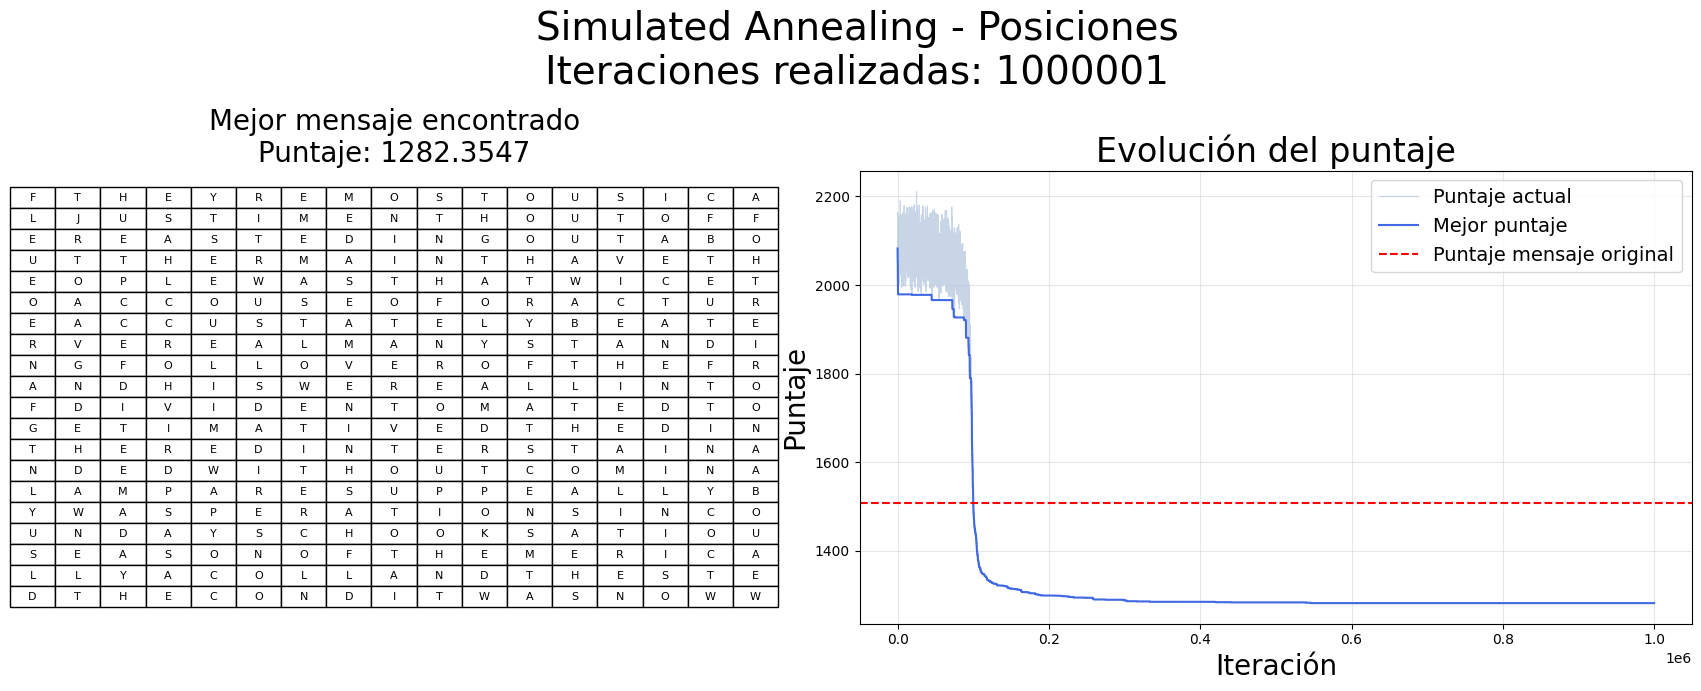

In [ ]:
mensaje, cuadricula = estimar_posiciones(M, lista_caract, Tiempo = 1e6, T_min=1e-80, esquema = "lineal")

--- Paso 1.000000e+06 | Temperatura: 1.000000e-80 ---
Mejor Funtion (Energía/Puntaje): 1319.6296421807808
Mejor Matriz M:
 [['X' 'C' 'O' 'M' 'I' 'N' 'A' 'L' 'P' 'R' 'O' 'M' 'P' 'L' 'E' 'T' 'O']
 ['T' 'H' 'E' 'S' 'O' 'F' 'R' 'O' 'M' 'F' 'O' 'R' 'D' 'E' 'P' 'A' 'R']
 ['K' 'E' 'L' 'Y' 'T' 'H' 'E' 'R' 'E' 'A' 'S' 'T' 'H' 'A' 'L' 'L' 'A']
 ['R' 'E' 'A' 'K' 'I' 'N' 'G' 'O' 'V' 'E' 'R' 'S' 'I' 'G' 'H' 'T' 'H']
 ['E' 'G' 'A' 'M' 'O' 'R' 'E' 'S' 'T' 'H' 'E' 'C' 'O' 'M' 'P' 'R' 'O']
 ['P' 'R' 'O' 'V' 'I' 'D' 'E' 'D' 'T' 'H' 'A' 'T' 'H' 'E' 'C' 'O' 'M']
 ['P' 'E' 'R' 'S' 'A' 'L' 'O' 'N' 'G' 'R' 'E' 'G' 'O' 'N' 'E' 'S' 'S']
 ['I' 'N' 'G' 'A' 'S' 'U' 'P' 'P' 'E' 'D' 'F' 'O' 'U' 'G' 'H' 'O' 'M']
 ['E' 'S' 'C' 'O' 'M' 'E' 'A' 'S' 'T' 'O' 'M' 'A' 'N' 'O' 'T' 'H' 'E']
 ['W' 'A' 'S' 'H' 'A' 'V' 'E' 'S' 'U' 'C' 'H' 'A' 'N' 'D' 'T' 'H' 'E']
 ['S' 'T' 'O' 'M' 'A' 'N' 'A' 'G' 'E' 'S' 'A' 'N' 'D' 'C' 'O' 'M' 'E']
 ['R' 'G' 'E' 'S' 'T' 'A' 'N' 'D' 'S' 'E' 'C' 'O' 'M' 'P' 'L' 'Y' 'G']
 ['O' 'T' 'A' 'K' 'E' 'A'

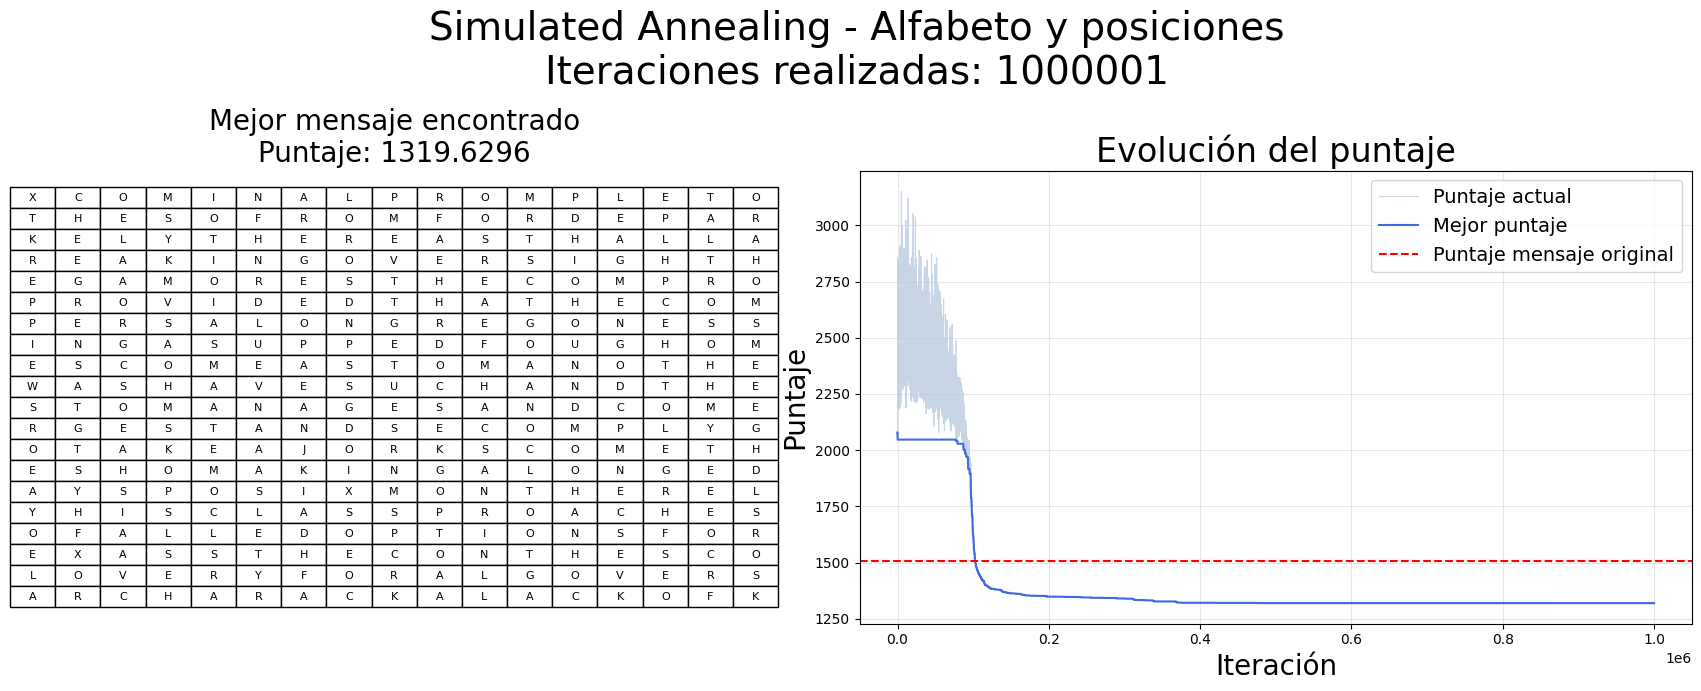

In [ ]:
mensaje, alfabeto, cuadricula = estimar_alfabeto_posiciones(M, lista_caract, Tiempo = 1e6, T_min=1e-80, esquema = "lineal")

### Esquema racional

Evaluando decimación (1,2)...


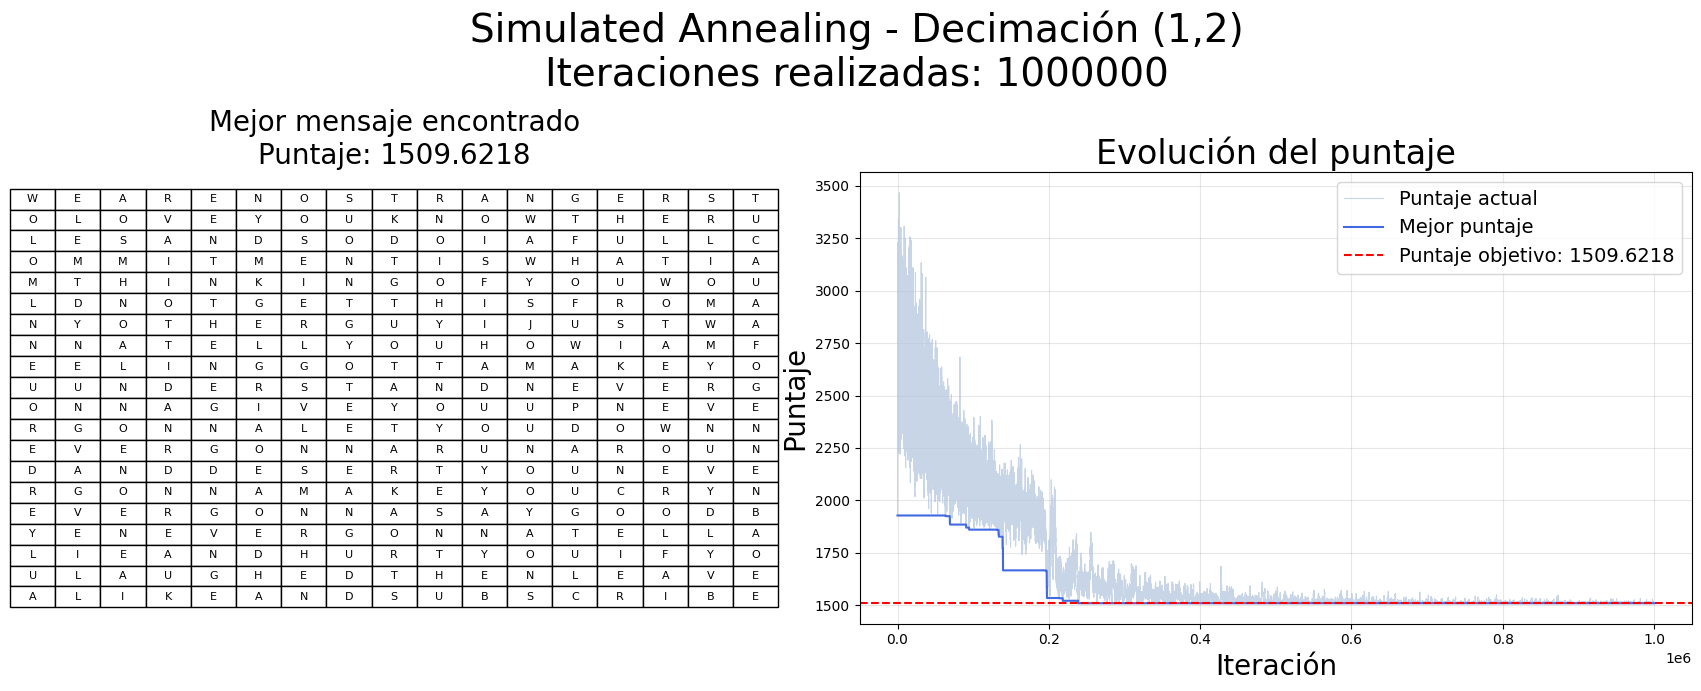

Evaluando decimación (19,15)...


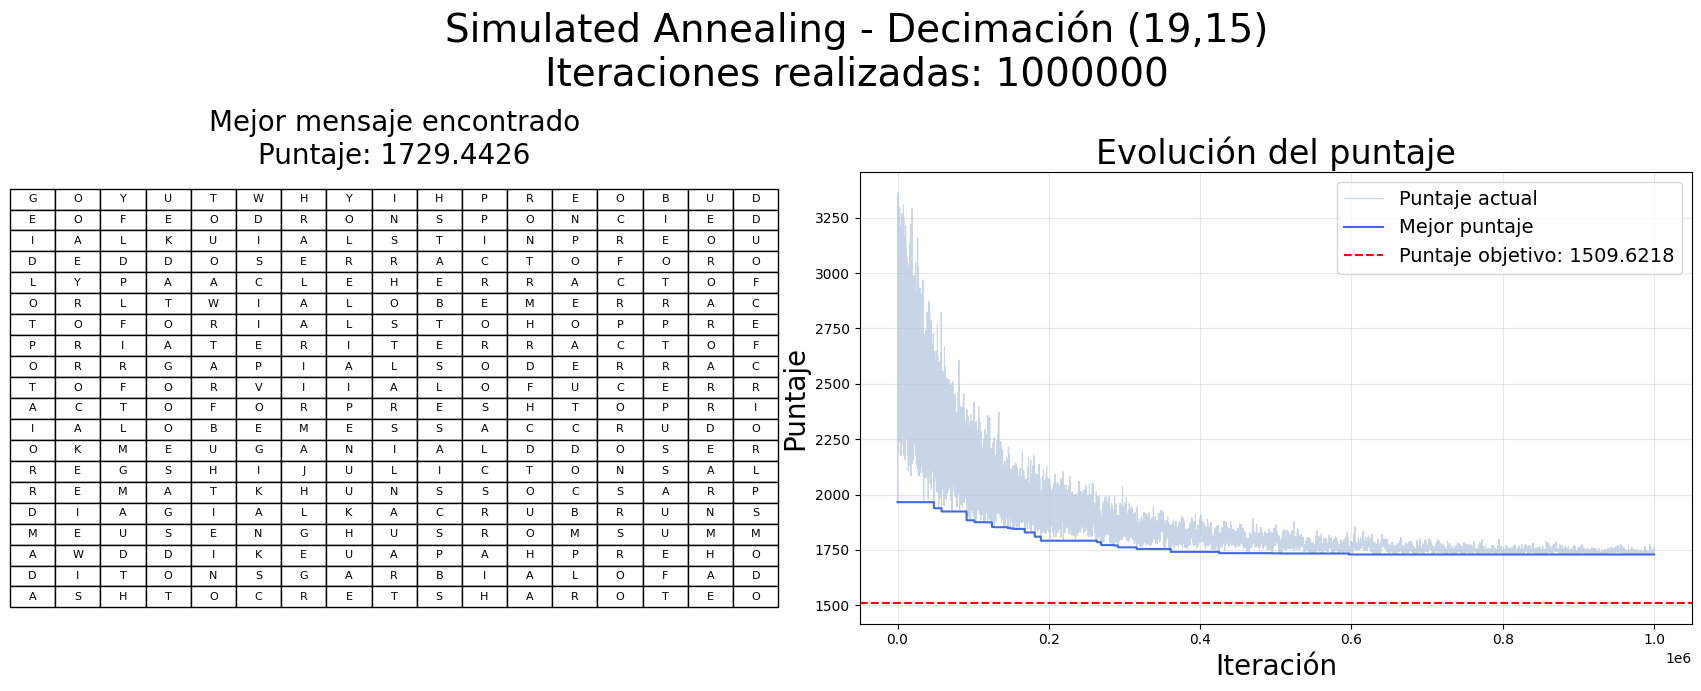

Evaluando decimación (3,6)...


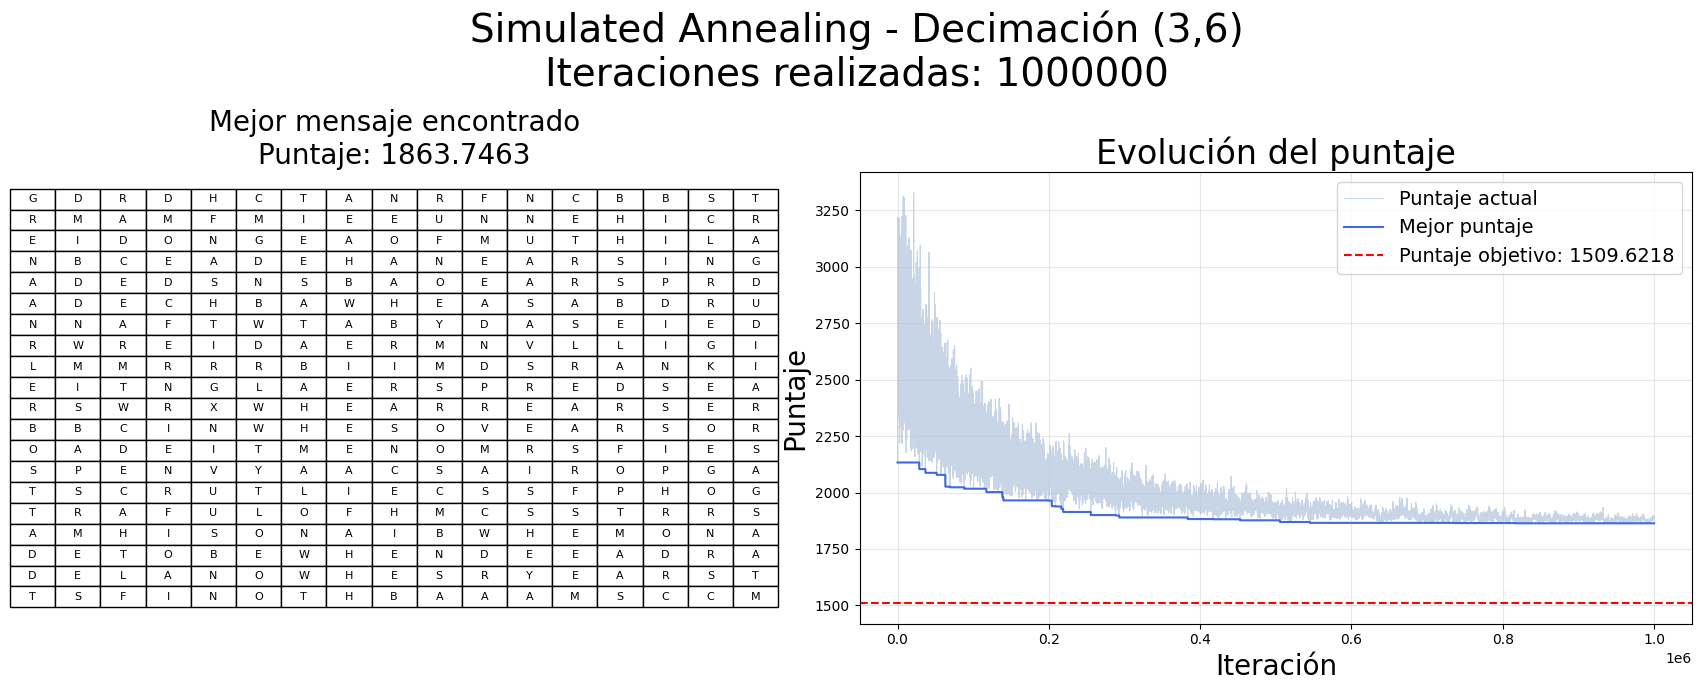

Evaluando decimación (17,11)...


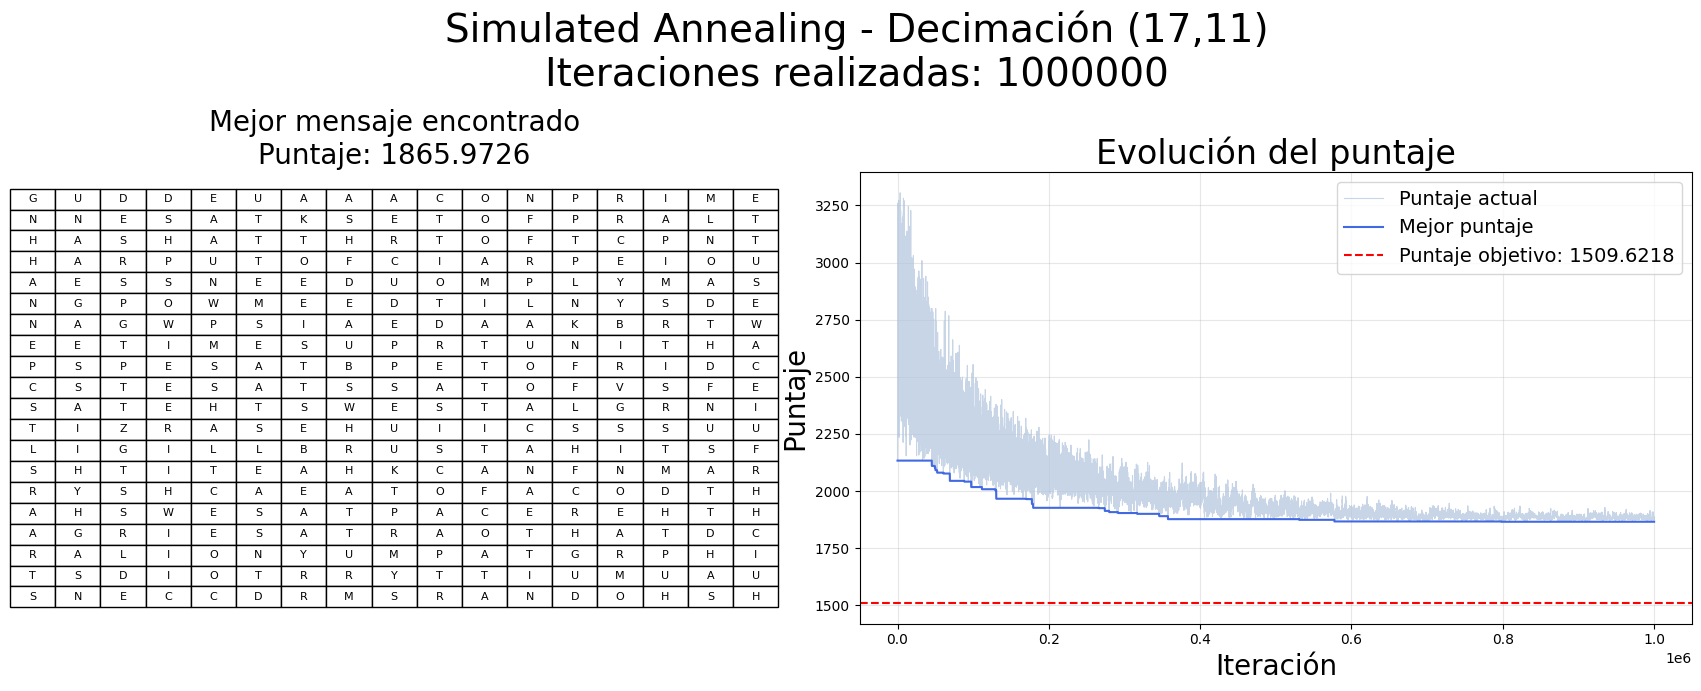

Evaluando decimación (7,2)...


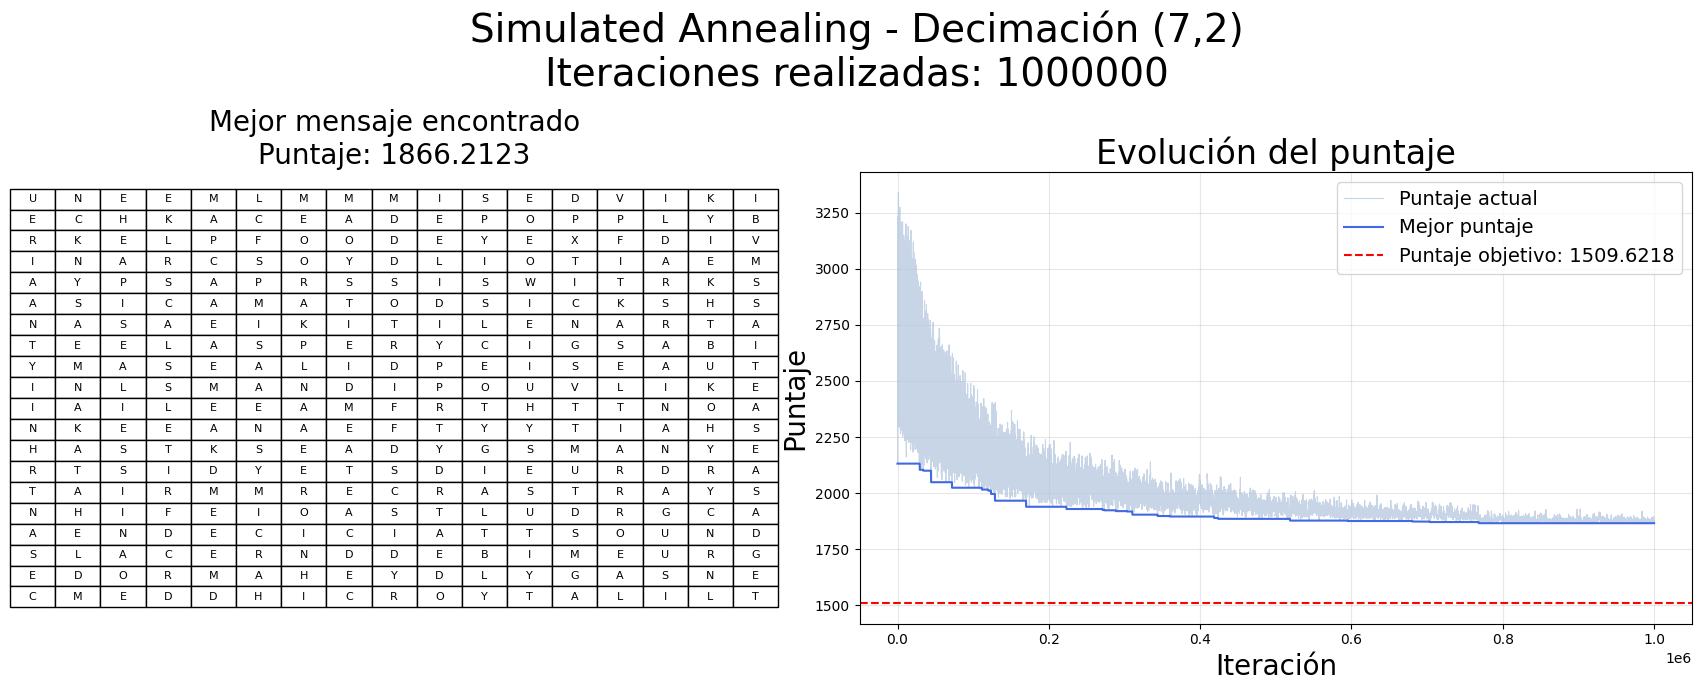

In [ ]:
mejores_decimaciones = [(1, 2), (19, 15), (3 ,6), (17, 11), (7, 2)]

resultados_SA = []

for a, b in mejores_decimaciones:

    print(f"Evaluando decimación ({a},{b})...")

    resultado = SimulatedAnnealing_decimaciones(
        M,
        lista_caract,
        df = a,
        dc = b,
        Tiempo = 1e6,
        M_objetivo = M_original,
        esquema = "racional",
        T0 = 2500
    )

    resultados_SA.append({
        "decimacion": (a, b),
        "mensaje": resultado[0],
        "sigma": resultado[1],
        "matriz": resultado[2]
    })

--- Paso 1.000000e+06 | Temperatura: 2.497502e+00 ---
Mejor Funcion (Energía/Puntaje): 1623.4335437623279
Mejor Matriz M:
 [['M' 'S' 'D' 'E' 'A' 'C' 'H' 'A' 'S' 'C' 'A' 'L' 'E' 'N' 'T' 'H' 'E']
 ['S' 'I' 'O' 'M' 'I' 'T' 'U' 'S' 'E' 'L' 'M' 'Y' 'P' 'O' 'A' 'T' 'E']
 ['D' 'M' 'I' 'T' 'J' 'L' 'Y' 'C' 'U' 'C' 'O' 'R' 'H' 'I' 'S' 'W' 'E']
 ['L' 'V' 'I' 'R' 'O' 'L' 'E' 'M' 'O' 'V' 'I' 'E' 'T' 'E' 'N' 'U' 'S']
 ['H' 'O' 'W' 'E' 'R' 'E' 'S' 'A' 'P' 'T' 'R' 'C' 'N' 'A' 'N' 'E' 'Y']
 ['A' 'T' 'T' 'E' 'C' 'H' 'O' 'P' 'E' 'S' 'A' 'L' 'I' 'E' 'F' 'E' 'A']
 ['T' 'A' 'T' 'H' 'U' 'L' 'D' 'I' 'T' 'E' 'N' 'T' 'E' 'R' 'N' 'C' 'I']
 ['A' 'L' 'D' 'R' 'U' 'F' 'O' 'U' 'T' 'O' 'R' 'C' 'O' 'T' 'W' 'O' 'A']
 ['N' 'D' 'A' 'W' 'A' 'W' 'A' 'N' 'S' 'E' 'T' 'O' 'R' 'T' 'A' 'N' 'D']
 ['I' 'V' 'I' 'T' 'A' 'R' 'S' 'P' 'O' 'U' 'H' 'O' 'F' 'O' 'R' 'U' 'T']
 ['A' 'N' 'S' 'I' 'N' 'T' 'T' 'O' 'S' 'U' 'E' 'V' 'I' 'E' 'T' 'Y' 'L']
 ['Y' 'N' 'U' 'T' 'O' 'C' 'E' 'E' 'F' 'T' 'F' 'V' 'E' 'S' 'T' 'L' 'A']
 ['B' 'A' 'B' 'U' 'T' 'W'

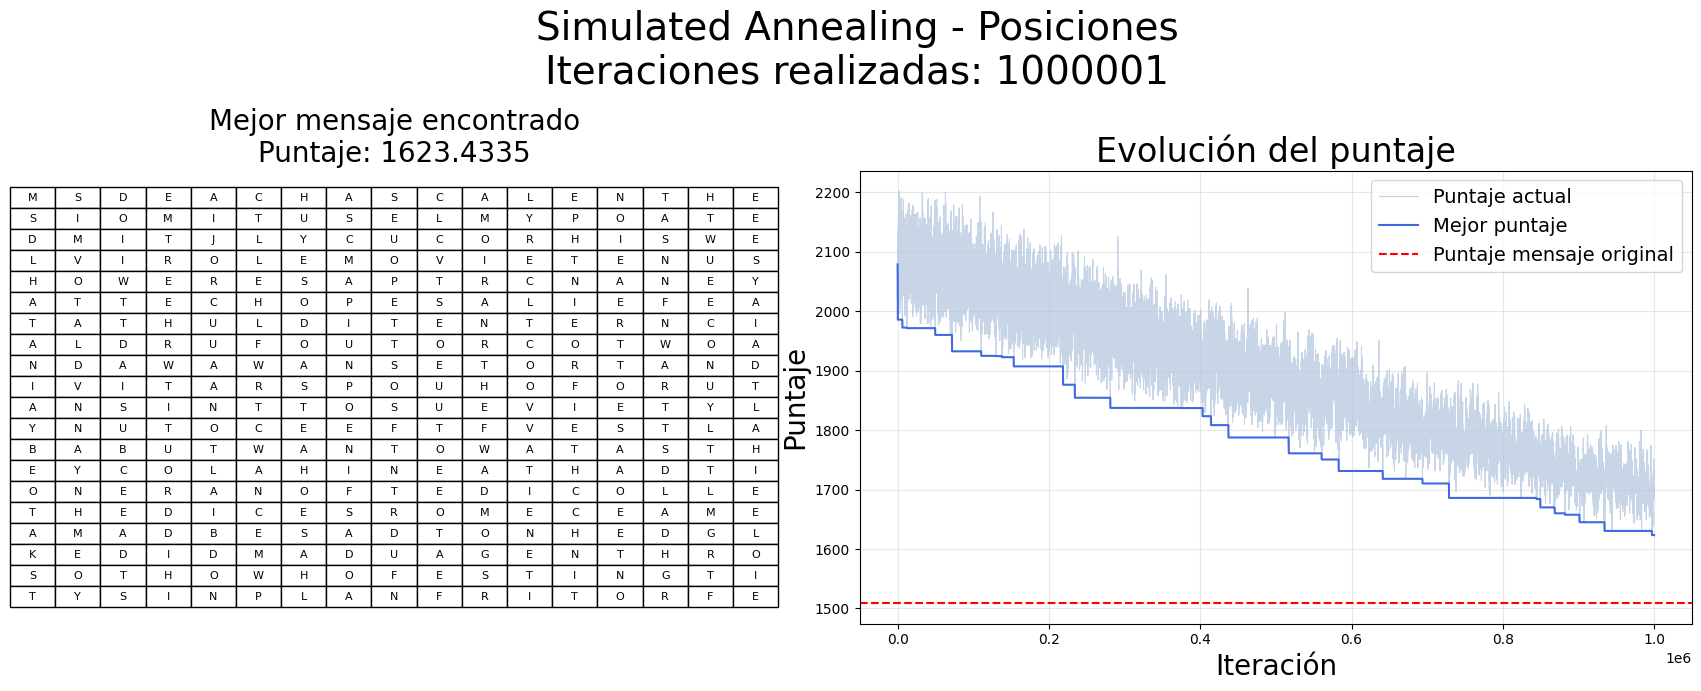

In [ ]:
mensaje, cuadricula = estimar_posiciones(M, lista_caract, Tiempo = 1e6, T_min=1e-80, esquema = "racional", T0 = 2500)

--- Paso 1.000000e+06 | Temperatura: 2.497502e+00 ---
Mejor Funtion (Energía/Puntaje): 1654.155250480699
Mejor Matriz M:
 [['H' 'V' 'P' 'M' 'G' 'O' 'L' 'I' 'S' 'H' 'T' 'O' 'A' 'K' 'R' 'I' 'C']
 ['A' 'B' 'S' 'C' 'R' 'E' 'A' 'D' 'E' 'T' 'I' 'R' 'O' 'W' 'L' 'E' 'D']
 ['C' 'A' 'R' 'W' 'I' 'T' 'E' 'T' 'I' 'N' 'D' 'I' 'T' 'D' 'R' 'E' 'S']
 ['H' 'E' 'A' 'L' 'S' 'O' 'H' 'E' 'A' 'R' 'E' 'E' 'A' 'U' 'N' 'G' 'S']
 ['W' 'I' 'T' 'K' 'I' 'B' 'P' 'H' 'I' 'S' 'B' 'I' 'R' 'E' 'M' 'E' 'S']
 ['C' 'O' 'R' 'P' 'L' 'I' 'S' 'I' 'S' 'O' 'D' 'E' 'T' 'A' 'M' 'E' 'G']
 ['E' 'D' 'E' 'R' 'E' 'F' 'U' 'L' 'W' 'A' 'T' 'C' 'I' 'S' 'S' 'U' 'R']
 ['I' 'S' 'A' 'W' 'E' 'P' 'O' 'G' 'Y' 'A' 'L' 'C' 'H' 'A' 'W' 'E' 'D']
 ['A' 'N' 'C' 'W' 'A' 'E' 'U' 'R' 'Y' 'I' 'M' 'E' 'G' 'W' 'F' 'A' 'C']
 ['H' 'E' 'S' 'A' 'R' 'G' 'U' 'E' 'A' 'R' 'S' 'H' 'N' 'I' 'G' 'N' 'A']
 ['N' 'G' 'K' 'E' 'R' 'C' 'H' 'C' 'O' 'P' 'R' 'I' 'N' 'C' 'T' 'O' 'N']
 ['C' 'E' 'S' 'A' 'N' 'E' 'A' 'L' 'E' 'L' 'E' 'P' 'K' 'I' 'L' 'S' 'E']
 ['T' 'I' 'S' 'T' 'O' 'S' 

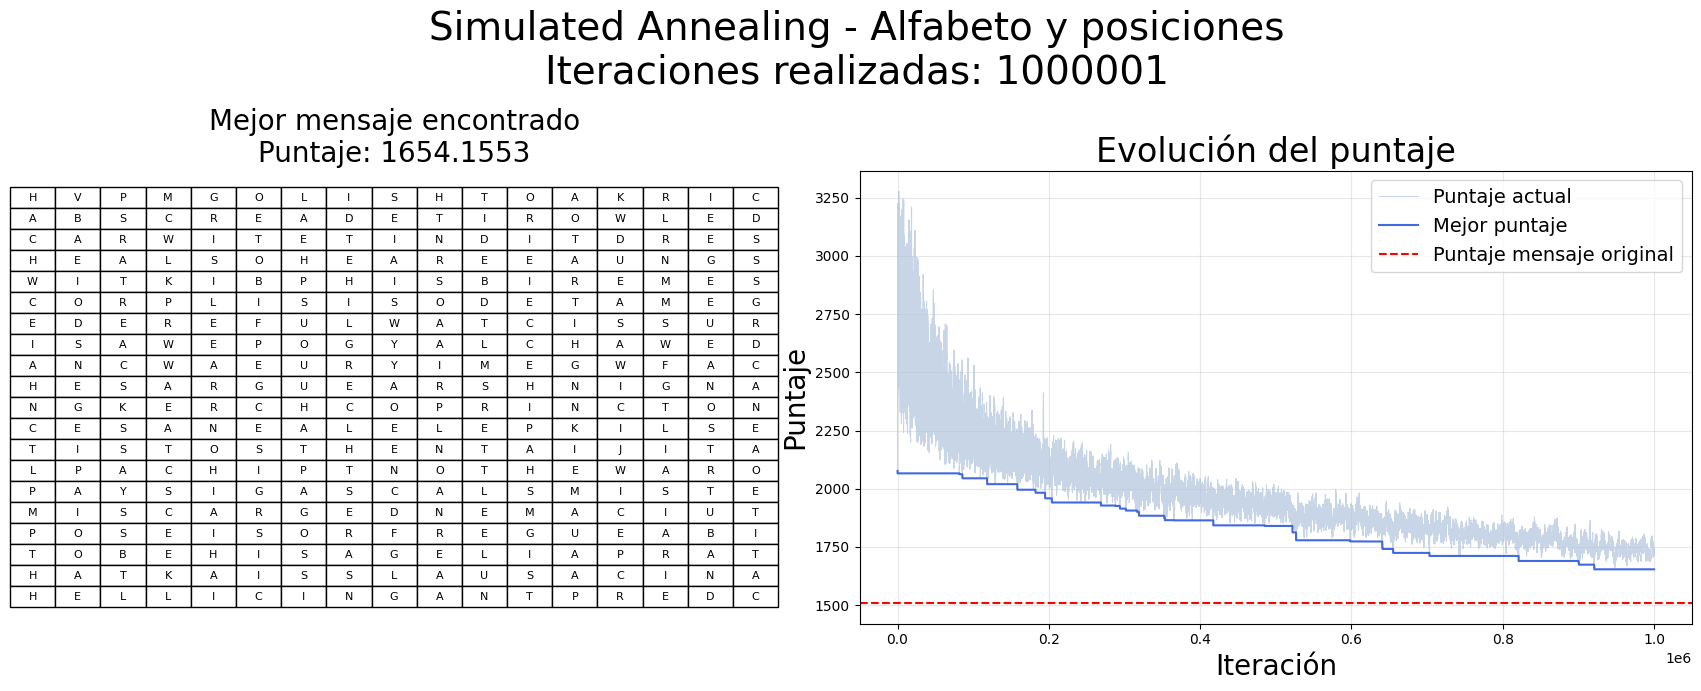

In [ ]:
mensaje, alfabeto, cuadricula = estimar_alfabeto_posiciones(M, lista_caract, Tiempo = 1e6, T_min=1e-80, esquema = "racional", T0 = 2500)

### Esquema de potencias

Evaluando decimación (1,2)...


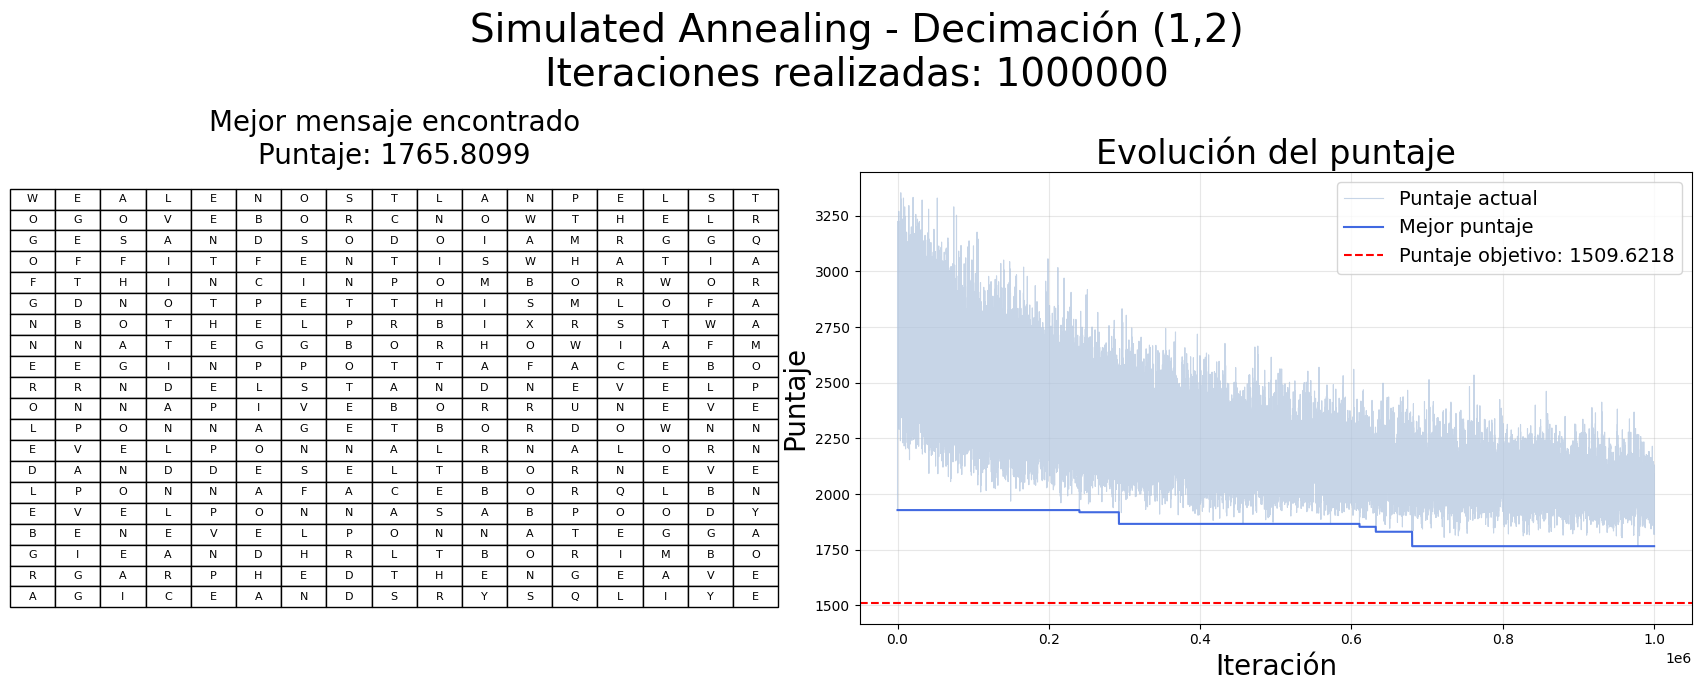

Evaluando decimación (19,15)...


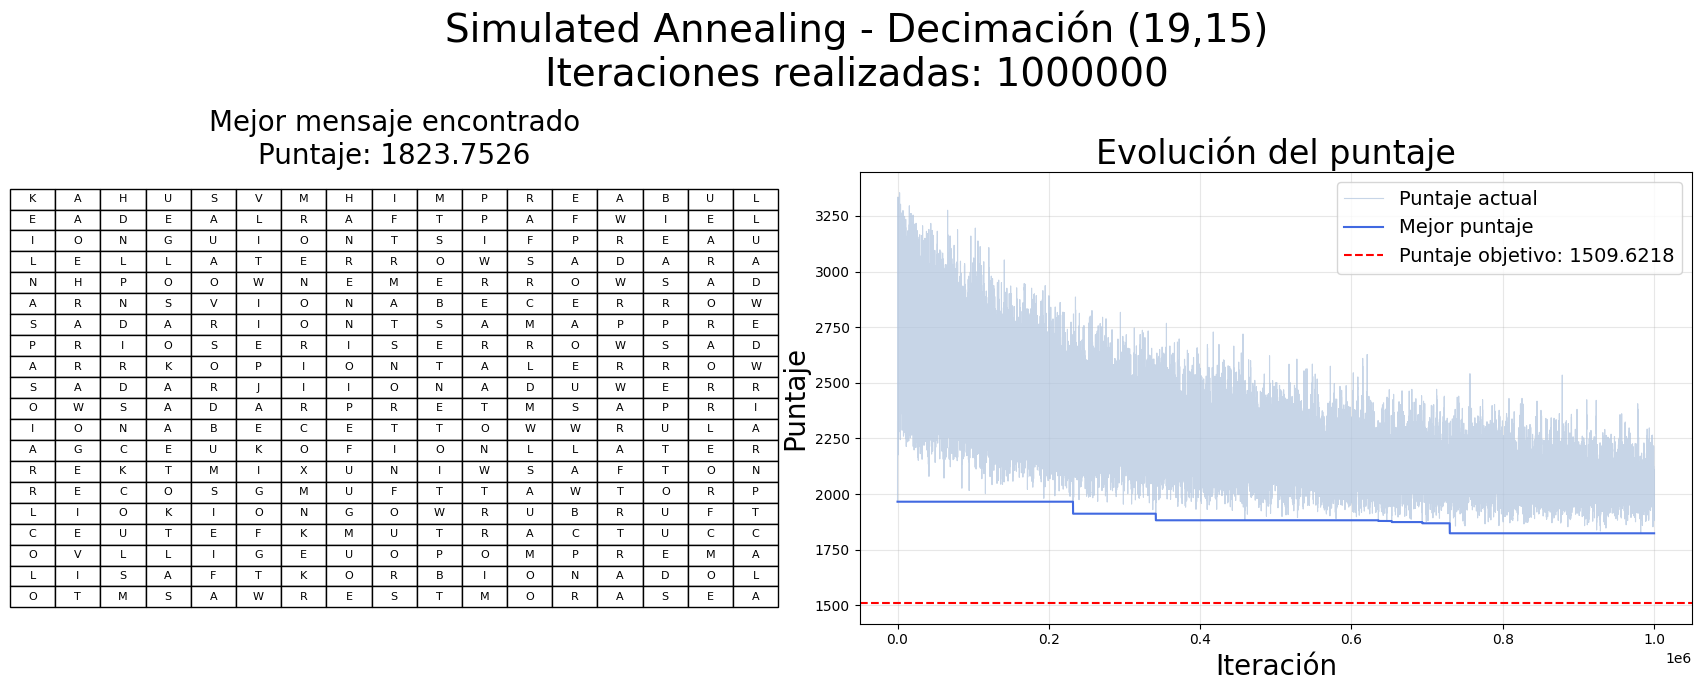

Evaluando decimación (3,6)...


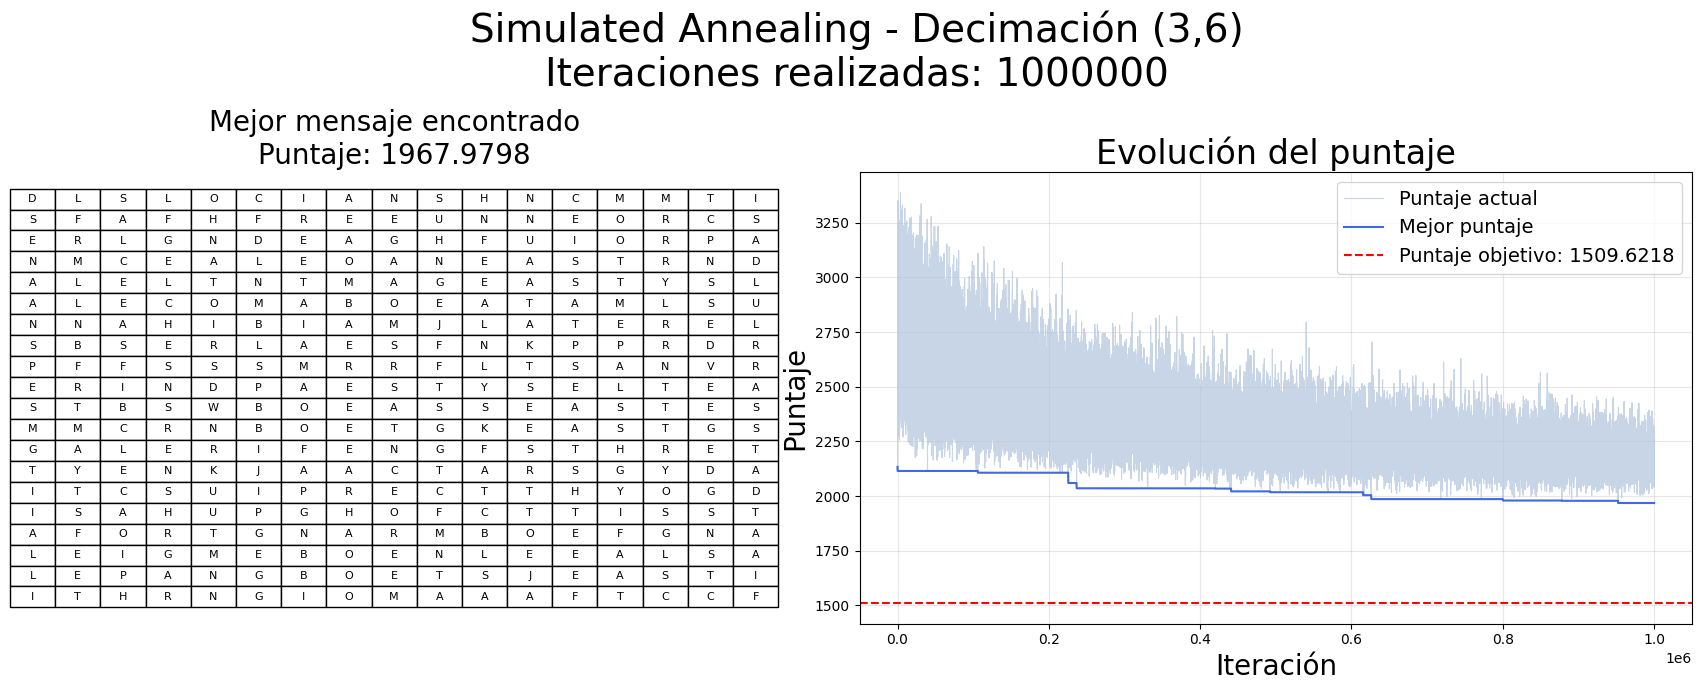

Evaluando decimación (17,11)...


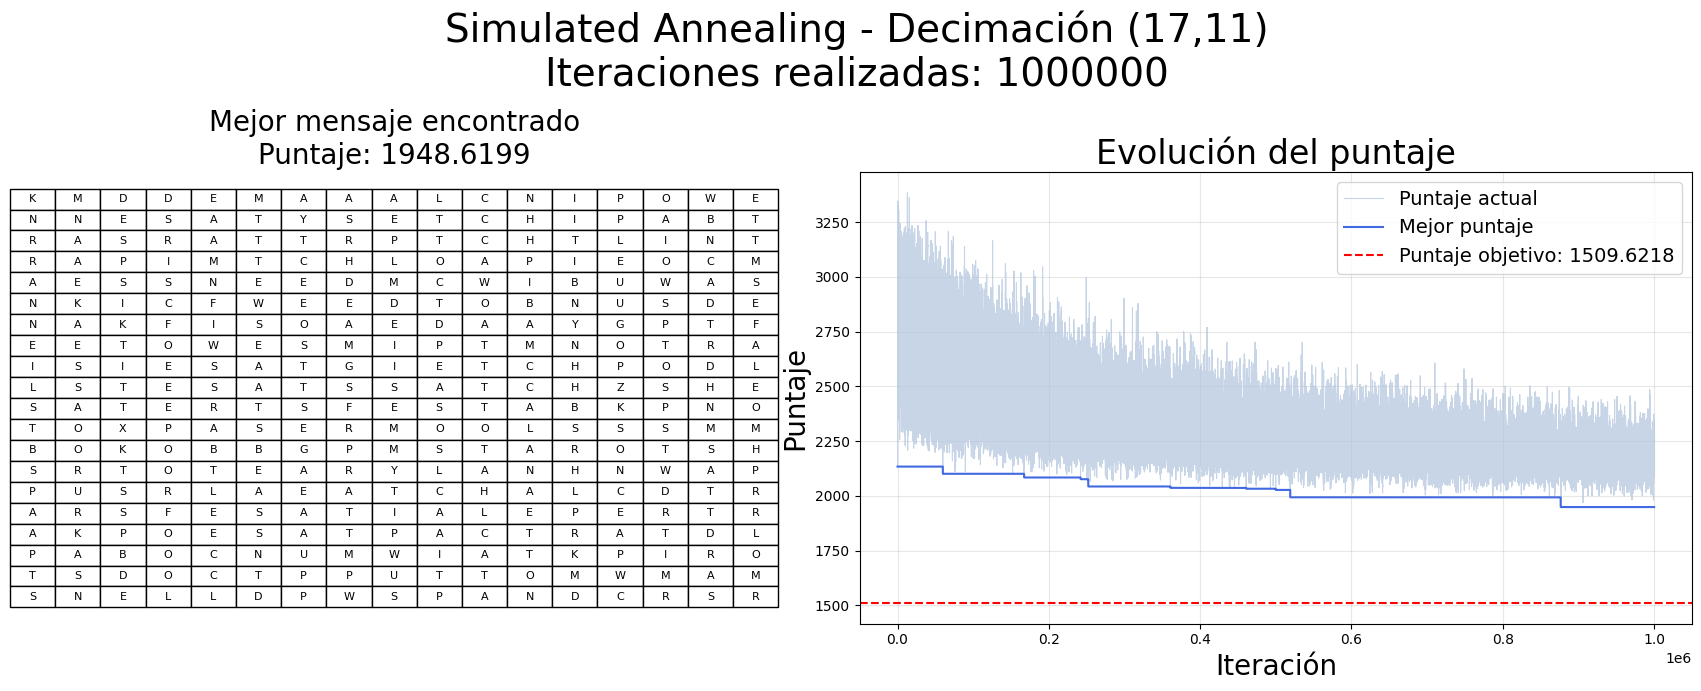

Evaluando decimación (7,2)...


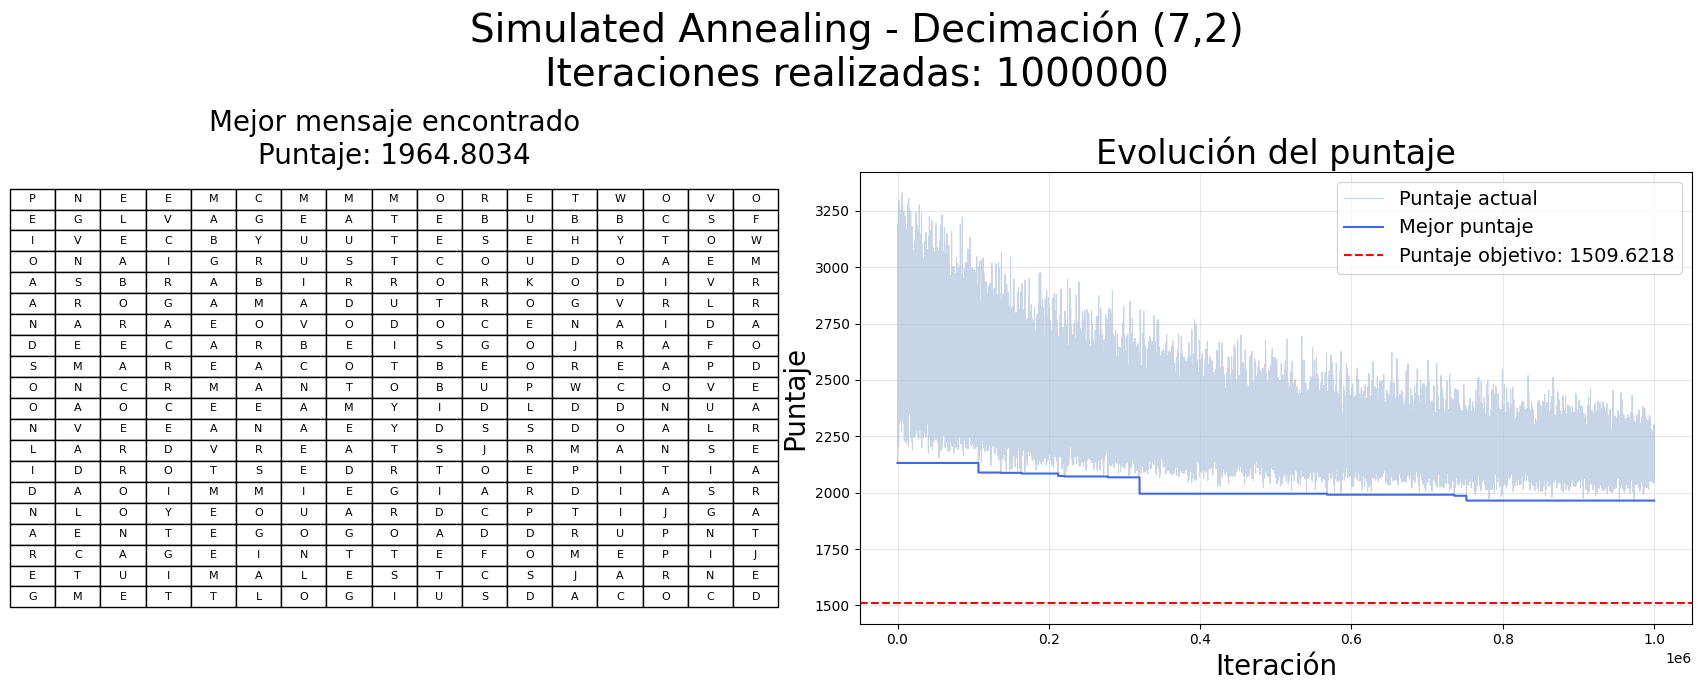

In [ ]:
mejores_decimaciones = [(1, 2), (19, 15), (3 ,6), (17, 11), (7, 2)]

resultados_SA = []

for a, b in mejores_decimaciones:

    print(f"Evaluando decimación ({a},{b})...")

    resultado = SimulatedAnnealing_decimaciones(
        M,
        lista_caract,
        df = a,
        dc = b,
        Tiempo = 1e6,
        M_objetivo = M_original,
        esquema = "potencias",
        p = 0.7,
        T0 = 2500
    )

    resultados_SA.append({
        "decimacion": (a, b),
        "mensaje": resultado[0],
        "sigma": resultado[1],
        "matriz": resultado[2]
    })

--- Paso 1.000000e+06 | Temperatura: 1.984432e+01 ---
Mejor Funcion (Energía/Puntaje): 1916.1554891607473
Mejor Matriz M:
 [['L' 'L' 'W' 'E' 'H' 'O' 'U' 'U' 'M' 'N' 'F' 'O' 'L' 'O' 'B' 'S' 'A']
 ['L' 'O' 'H' 'I' 'S' 'H' 'W' 'C' 'R' 'O' 'T' 'E' 'F' 'E' 'P' 'A' 'H']
 ['E' 'C' 'A' 'L' 'T' 'A' 'F' 'T' 'E' 'S' 'E' 'M' 'D' 'I' 'C' 'I' 'T']
 ['A' 'G' 'N' 'A' 'I' 'C' 'T' 'I' 'Y' 'E' 'A' 'Y' 'R' 'T' 'A' 'I' 'O']
 ['T' 'M' 'R' 'U' 'S' 'E' 'A' 'W' 'O' 'N' 'I' 'A' 'N' 'R' 'E' 'Y' 'A']
 ['R' 'P' 'N' 'I' 'E' 'E' 'T' 'E' 'A' 'T' 'A' 'F' 'C' 'O' 'C' 'T' 'F']
 ['S' 'I' 'R' 'V' 'I' 'E' 'E' 'A' 'T' 'C' 'E' 'S' 'W' 'H' 'I' 'R' 'T']
 ['A' 'T' 'O' 'L' 'M' 'E' 'R' 'O' 'H' 'N' 'U' 'R' 'E' 'T' 'E' 'D' 'A']
 ['C' 'U' 'S' 'I' 'I' 'V' 'D' 'S' 'O' 'N' 'E' 'H' 'N' 'E' 'T' 'T' 'W']
 ['O' 'E' 'N' 'Y' 'I' 'U' 'N' 'U' 'N' 'R' 'U' 'O' 'S' 'N' 'D' 'A' 'A']
 ['T' 'L' 'U' 'A' 'T' 'L' 'I' 'B' 'O' 'A' 'F' 'T' 'K' 'C' 'A' 'N' 'E']
 ['S' 'S' 'D' 'C' 'A' 'S' 'E' 'T' 'H' 'Y' 'C' 'N' 'D' 'H' 'O' 'N' 'T']
 ['E' 'T' 'E' 'D' 'A' 'F'

/tmp/ipykernel_577/2217078796.py:156: UserWarning: Creating legend with loc="best" can be slow with large amounts of data.
  plt.savefig(f"Simulated Annealing - Posiciones - Esquema {esquema}.jpg")
/tmp/ipykernel_577/2217078796.py:157: UserWarning: Creating legend with loc="best" can be slow with large amounts of data.
  plt.tight_layout()
/usr/local/lib/python3.13/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Creating legend with loc="best" can be slow with large amounts of data.
  fig.canvas.print_figure(bytes_io, **kw)


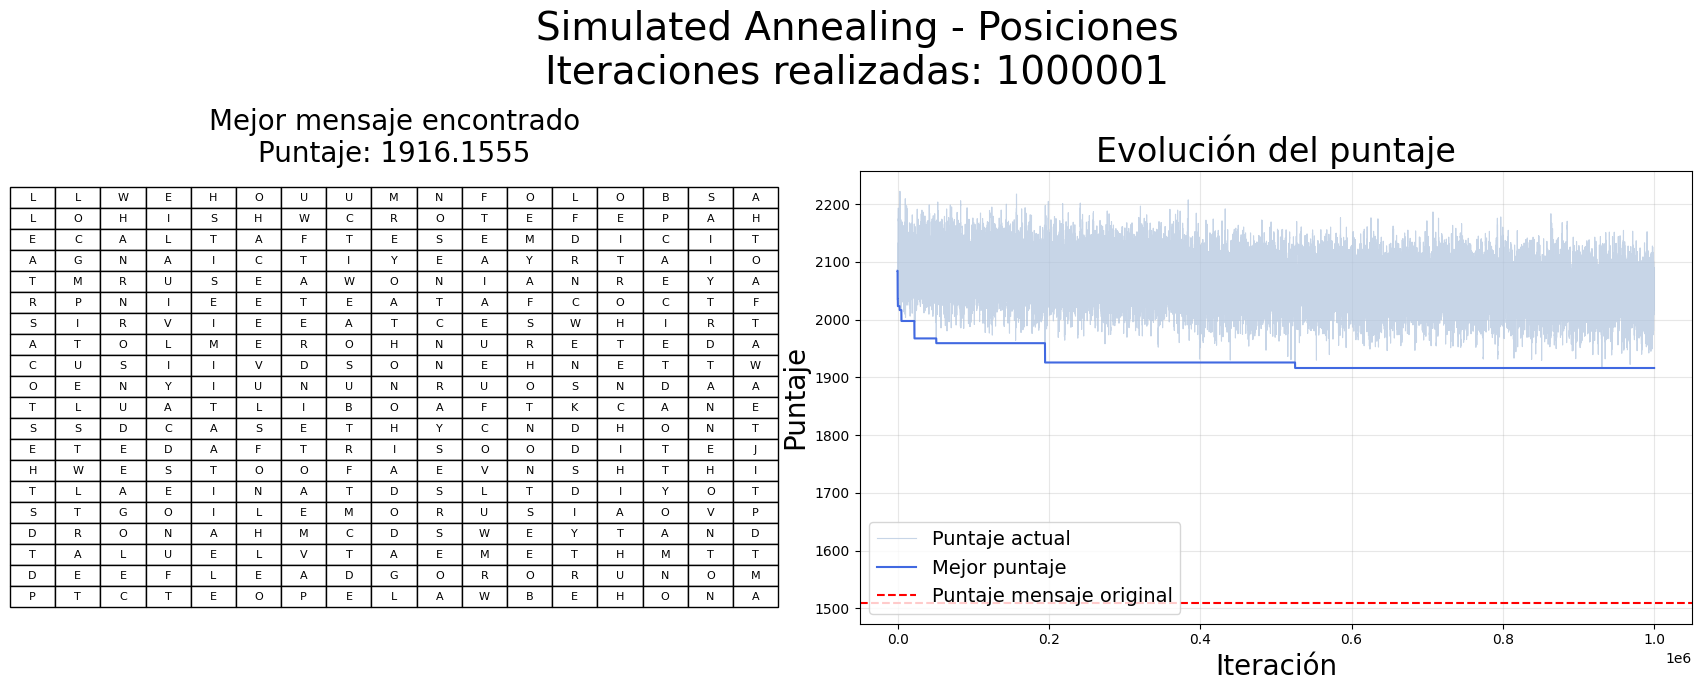

In [ ]:
mensaje, cuadricula = estimar_posiciones(M, lista_caract, Tiempo = 1e6, T_min=1e-80, esquema = "potencias", p = 0.7, T0 = 2500)

--- Paso 1.000000e+06 | Temperatura: 1.984432e+01 ---
Mejor Funtion (Energía/Puntaje): 2007.863288471344
Mejor Matriz M:
 [['G' 'S' 'R' 'O' 'E' 'E' 'P' 'E' 'R' 'E' 'E' 'I' 'L' 'U' 'N' 'R' 'E']
 ['Y' 'R' 'A' 'L' 'D' 'O' 'R' 'O' 'A' 'O' 'T' 'G' 'R' 'P' 'E' 'I' 'I']
 ['R' 'R' 'I' 'R' 'I' 'G' 'N' 'F' 'R' 'S' 'W' 'G' 'T' 'R' 'R' 'A' 'Y']
 ['I' 'E' 'W' 'Y' 'R' 'I' 'M' 'C' 'A' 'R' 'I' 'Z' 'E' 'E' 'E' 'R' 'I']
 ['A' 'L' 'D' 'S' 'E' 'R' 'Y' 'N' 'A' 'I' 'D' 'A' 'U' 'W' 'O' 'O' 'N']
 ['D' 'N' 'P' 'I' 'S' 'I' 'N' 'A' 'Y' 'A' 'R' 'N' 'D' 'P' 'I' 'E' 'H']
 ['O' 'R' 'Y' 'I' 'A' 'W' 'H' 'Z' 'C' 'P' 'A' 'D' 'E' 'S' 'W' 'A' 'H']
 ['M' 'A' 'D' 'E' 'R' 'U' 'T' 'M' 'A' 'O' 'I' 'A' 'L' 'D' 'L' 'I' 'E']
 ['U' 'O' 'T' 'W' 'I' 'G' 'M' 'I' 'T' 'E' 'I' 'D' 'M' 'M' 'A' 'I' 'N']
 ['D' 'M' 'N' 'C' 'E' 'E' 'O' 'N' 'N' 'H' 'E' 'E' 'R' 'I' 'R' 'T' 'M']
 ['E' 'N' 'S' 'I' 'C' 'E' 'R' 'O' 'T' 'C' 'T' 'A' 'R' 'Y' 'Y' 'K' 'O']
 ['E' 'W' 'R' 'W' 'A' 'R' 'S' 'G' 'T' 'K' 'C' 'A' 'A' 'W' 'R' 'B' 'L']
 ['W' 'O' 'U' 'S' 'R' 'E' 

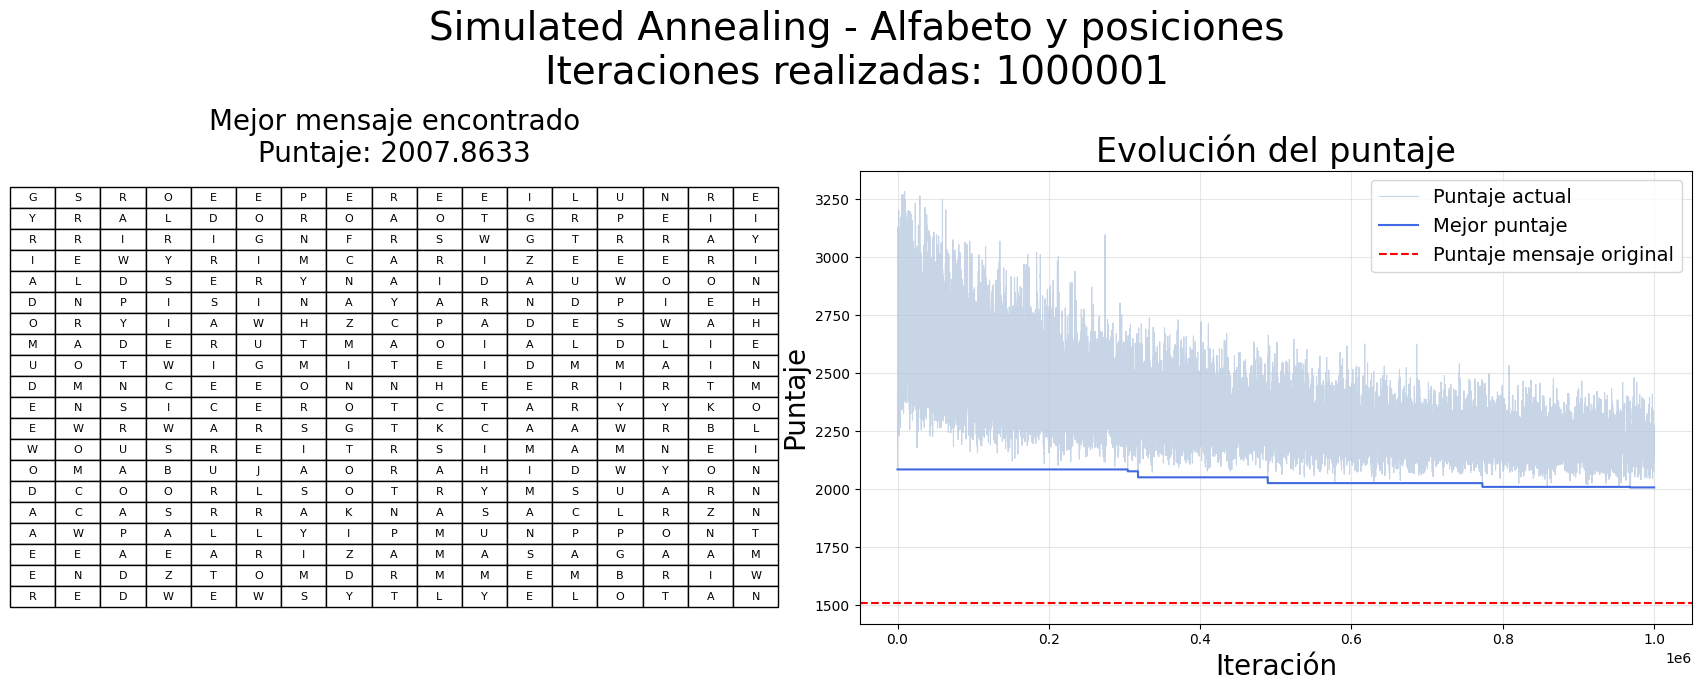

In [ ]:
mensaje, alfabeto, cuadricula = estimar_alfabeto_posiciones(M, lista_caract, Tiempo = 1e6, T_min=1e-80, esquema = "potencias", p = 0.7, T0 = 2500)